# Sanktionen gegen den Iran, 1979–2025

Analyse aller erfassten Sanktionsfälle gegen den Iran und ihre Einordnung in das weltweite Sanktionsgeschehen,
auf Grundlage der **Global Sanctions Data Base (GSDB)** und ihrer neuen Erweiterung zu Finanzsanktionen.

**Forschungsfragen**
1. Wie haben sich die Sanktionen gegen den Iran entwickelt, und wer hat sie verhängt?
2. Welche Instrumente wurden eingesetzt, insbesondere welche Finanzmaßnahmen?
3. Warum wurden Sanktionen verhängt, und wie endeten sie?
4. Wie steht der Iran im Vergleich zu anderen sanktionierten Ländern und zu den wichtigsten Sanktionsakteuren da?

**Daten**
- GSDB Release 5 (GSDB-R5): 1.794 Sanktionsfälle weltweit, 1949–2025
- GSDB Financial Sanctions (GSDB-FS): Unterarten der Finanzsanktionen für die 1.072 Fälle mit Finanzkomponente
- Die Daten sind auf Anfrage unter [globalsanctionsdatabase.com/data](https://www.globalsanctionsdatabase.com/data/) erhältlich.
  Sie dürfen nicht weitergegeben werden, deshalb sind die Rohdaten **nicht** Teil dieses Repositorys.

**Aufbau**
1. Setup & Importe
2. Daten laden & Qualitätsprüfung
3. Iran-Auswahl
4. Entwicklung im Zeitverlauf
5. Wer sanktioniert den Iran?
6. Sanktionsinstrumente
7. Ziele und Ergebnisse
8. Der Iran im weltweiten Vergleich
9. Export für das Dashboard
10. Wichtigste Ergebnisse
11. Limitations
12. Quellen

**Diagramme:** gespeichert in `images/`, Englisch als `<name>.png`, Deutsch als `<name>_de.png`, Karten als `.html`.

*Kein Vorhersagemodell: Der Schwerpunkt liegt auf Datenaufbereitung, explorativer Analyse und Visualisierung.*

## 1. Setup & Importe

Benötigte Pakete: `pandas`, `matplotlib`, `plotly`, `country_converter`.
Fehlt ein Paket, im Notebook-Environment installieren, z. B. `%pip install country_converter`.

Dieser Abschnitt definiert auch die Hilfsobjekte, die im ganzen Notebook genutzt werden:
- **`split_parties`**: Sender- und Zielfelder können mehrere Parteien in einem kommagetrennten Text enthalten.
  Einige Ländernamen enthalten selbst ein Komma (z. B. *Korea, South*) und dürfen nicht getrennt werden.
- **`cases_in_force`**: Anzahl der Fälle in Kraft pro Jahr (von `begin_year` bis `end_year`).
- **EU-Mitgliedschaft nach Beitrittsdatum**: Fälle der EU (und ihrer Vorgängerin, der EWG) werden den Ländern zugeordnet,
  die bei Beginn des Falls Mitglied waren (geprüft nach Jahr und Monat).
- **Zweisprachige Diagramme**: `lab` übersetzt Kategorien aus den Daten ins Deutsche, `chart_footer` schreibt Erklärung,
  Quelle und Autor unter jedes Diagramm, `save_chart` und `save_map` speichern die englische und die deutsche Fassung.

Die Kategorien in den Tabellen (z. B. *Trade*, *Failed*) bleiben englisch, weil das Dashboard die exportierten Tabellen
liest und selbst übersetzt. Übersetzt werden nur die Diagramme.

In [1]:
import logging
from pathlib import Path

import country_converter as coco
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

logging.getLogger("country_converter").setLevel(logging.CRITICAL)

# Dateipfade (Rohdaten sind nicht im Repository enthalten)
R5_PATH = "GSDB-R5/GSDB-R5.csv"
FS_PATH = "GSDB-FS/GSDB-FS.csv"

# Ordner für die Diagramme
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

# Farben für alle Diagramme
COLOR_MAIN = "#1f4e79"    # Iran / Hauptreihe
COLOR_LIGHT = "#6fa8dc"   # zweite Reihe
COLOR_WORLD = "#bdbdbd"   # Vergleich: alle Sanktionen weltweit
COLOR_DARK = "#5f6368"    # dritte Reihe / Nebentext
COLOR_NEW = "#c0392b"     # Hervorhebung: neue Fälle

# Sprachen der Diagramme: Deutsch wird im Notebook angezeigt, Englisch nur gespeichert
LANGS = ["de", "en"]

# Quellen- und Autorenangaben für die Diagramme
DATA_NOTE_R5 = {
    "en": "Data: Global Sanctions Data Base, Release 5 (Felbermayr et al., 2020).",
    "de": "Daten: Global Sanctions Data Base, Release 5 (Felbermayr et al., 2020).",
}
DATA_NOTE_FS = {
    "en": "Data: Global Sanctions Data Base – Financial Sanctions (Yotov et al., 2026).",
    "de": "Daten: Global Sanctions Data Base – Financial Sanctions (Yotov et al., 2026).",
}
AUTHOR_NOTE = {
    "en": "Analysis and chart: Amirhoushang Rahmannejad, github.com/Amirhouschang",
    "de": "Analyse und Grafik: Amirhoushang Rahmannejad, github.com/Amirhouschang",
}

# Muster für den Iran als Partei (einzige Partei oder eine von mehreren)
IRAN_PATTERN = r"\bIran\b"

# Ländernamen mit Komma, die nicht getrennt werden dürfen
COMMA_NAMES = [
    "Egypt, Arab Rep.", "Bahamas, The", "Gambia, The",
    "Congo, Democratic Republic of the", "Korea, North", "Korea, South", "Yemen, North",
]


def split_parties(value):
    """Teilt einen Sender- oder Zieltext in einzelne Parteien; Namen mit Komma bleiben erhalten."""
    for i, name in enumerate(COMMA_NAMES):
        value = value.replace(name, f"__{i}__")
    parties = [p.strip() for p in value.split(",")]
    for i, name in enumerate(COMMA_NAMES):
        parties = [name if p == f"__{i}__" else p for p in parties]
    return parties


def cases_in_force(cases, years):
    """Anzahl der Fälle in Kraft pro Jahr (ein Fall zählt von begin_year bis end_year)."""
    return pd.Series({
        y: ((cases["begin_year"] <= y) & (cases["end_year"] >= y)).sum()
        for y in years
    })


# EU-Mitgliedsstaaten (ISO3) mit Beitrittsdatum (EWG/EG/EU) als (Jahr, Monat)
EU_MEMBERS = {
    "AUT": (1995, 1), "BEL": (1958, 1), "BGR": (2007, 1), "HRV": (2013, 7), "CYP": (2004, 5), "CZE": (2004, 5),
    "DNK": (1973, 1), "EST": (2004, 5), "FIN": (1995, 1), "FRA": (1958, 1), "DEU": (1958, 1), "GRC": (1981, 1),
    "HUN": (2004, 5), "IRL": (1973, 1), "ITA": (1958, 1), "LVA": (2004, 5), "LTU": (2004, 5), "LUX": (1958, 1),
    "MLT": (2004, 5), "NLD": (1958, 1), "POL": (2004, 5), "PRT": (1986, 1), "ROU": (2007, 1), "SVK": (2004, 5),
    "SVN": (2004, 5), "ESP": (1986, 1), "SWE": (1995, 1), "GBR": (1973, 1),
}
# Erster Monat ohne Mitgliedschaft: Großbritannien trat am 31. Januar 2020 aus
EU_EXITS = {"GBR": (2020, 2)}

# Monatsnamen in den Daten (begin_month) als Zahlen
MONTHS = {name: i for i, name in enumerate(
    ["January", "February", "March", "April", "May", "June", "July",
     "August", "September", "October", "November", "December"], start=1)}

# Historische Staaten erscheinen auf Karten unter dem heutigen Nachfolgestaat
HISTORICAL_STATES = {
    "Soviet Union": "RUS", "German Democratic Republic": "DEU",
    "Malaya": "MYS", "South Vietnam": "VNM",
    "FRY": "SRB",  # Bundesrepublik Jugoslawien
}

# Wichtige Ereignisse als Referenzlinien in Zeitdiagrammen (englisch, wird so exportiert)
KEY_EVENTS = {
    1979: "Revolution, hostage crisis",
    1984: "US terrorism designation",
    1995: "US trade embargo",
    2006: "First UN sanctions",
    2012: "EU oil embargo, SWIFT",
    2016: "JCPOA implemented",
    2018: "US leaves JCPOA",
    2022: "Woman, Life, Freedom protests",
    2025: "UN snapback",
}
KEY_EVENTS_DE = {
    1979: "Revolution, Geiselkrise",
    1984: "US-Terrorliste",
    1995: "US-Handelsembargo",
    2006: "Erste UN-Sanktionen",
    2012: "EU-Ölembargo, SWIFT",
    2016: "JCPOA umgesetzt",
    2018: "US-Ausstieg aus dem JCPOA",
    2022: "Proteste „Frau, Leben, Freiheit“",
    2025: "UN-Snapback",
}

# Deutsche Übersetzung der Kategorien aus den Daten (wie im Dashboard)
LABELS_DE = {
    # Instrumente
    "Trade": "Handel", "Financial": "Finanzen", "Travel": "Reisen", "Arms": "Waffen",
    "Military assistance": "Militärhilfe", "Other": "Sonstiges",
    # Arten von Finanzsanktionen
    "Asset freeze": "Vermögenssperre", "Financial services": "Finanzdienstleistungen",
    "Investment restrictions": "Investitionsverbote",
    "Payment infrastructure (e.g. SWIFT)": "Zahlungsinfrastruktur (z. B. SWIFT)",
    "Aid": "Entwicklungshilfe",
    # Ergebnisse
    "Full success": "Voller Erfolg", "Partial success": "Teilerfolg",
    "Negotiated settlement": "Verhandlungslösung", "Failed": "Gescheitert",
    # Ziele
    "Nuclear / threat to peace": "Atomprogramm / Friedensbedrohung", "Terrorism": "Terrorismus",
    "Human rights": "Menschenrechte", "Policy change": "Politikwechsel", "End war": "Kriegsende",
    "Democracy": "Demokratie", "Destabilise regime": "Regimedestabilisierung",
    "Territorial conflict": "Territorialkonflikt",
}


def lab(value, lang):
    """Übersetzt eine Kategorie aus den Daten in die Sprache des Diagramms."""
    return LABELS_DE.get(value, value) if lang == "de" else value


def pct(value, lang):
    """Prozentangabe: deutsch mit Leerzeichen (86 %), englisch ohne (86%)."""
    return f"{value:.0f} %" if lang == "de" else f"{value:.0f}%"


def chart_footer(fig, lines, lang, data_note, y=-0.02):
    """Schreibt Erklärung, Datenquelle und Autor unter das Diagramm."""
    text = "\n".join(lines + [data_note[lang], AUTHOR_NOTE[lang]])
    fig.text(0.01, y, text, fontsize=9, va="top")


def save_chart(fig, name, lang):
    """Speichert ein matplotlib-Diagramm (en: images/<name>.png, de: images/<name>_de.png).

    Die deutsche Fassung wird im Notebook angezeigt, die englische nur gespeichert.
    """
    filename = f"{name}.png" if lang == "en" else f"{name}_de.png"
    fig.savefig(IMAGES_DIR / filename, dpi=150, bbox_inches="tight")
    if lang == "de":
        plt.show()
    else:
        plt.close(fig)


def save_map(fig, name, lang):
    """Speichert eine plotly-Karte als interaktive HTML-Datei und, falls kaleido installiert ist, als PNG."""
    stem = name if lang == "en" else f"{name}_de"
    fig.write_html(IMAGES_DIR / f"{stem}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(IMAGES_DIR / f"{stem}.png", width=1200, height=650, scale=2)
    except Exception:
        pass  # PNG nur mit kaleido; die HTML-Datei ist immer vorhanden
    if lang == "de":
        fig.show()

## 2. Daten laden & Qualitätsprüfung

Grundlegender Überblick über beide Dateien: Größe, Datentypen, fehlende Werte, Duplikate und abgedeckte Jahre.

In [2]:
r5 = pd.read_csv(R5_PATH)
fs = pd.read_csv(FS_PATH)

for name, df in [("GSDB-R5", r5), ("GSDB-FS", fs)]:
    print(f"== {name}: {df.shape[0]} Zeilen, {df.shape[1]} Spalten")
    print(df.dtypes)
    print("Fehlende Werte:\n", df.isna().sum()[df.isna().sum() > 0])
    print("Doppelte Zeilen:", df.duplicated().sum())
    print("Doppelte case_id:", df["case_id"].duplicated().sum())
    print("Jahre:", df["begin_year"].min(), "–", df["begin_year"].max(), "\n")

# Laufende Fälle werden über success erkannt, da end_year bei ihnen auf 2025 gesetzt ist
print("Laufende Fälle (R5):", r5["success"].str.contains("ongoing").sum())
print("Fälle mit end_year 2025 (R5):", (r5["end_year"] == 2025).sum())

== GSDB-R5: 1794 Zeilen, 18 Spalten
case_id               int64
sanctioned_state     object
sanctioning_state    object
begin_year            int64
begin_month          object
end_year              int64
end_month            object
trade                 int64
descr_trade          object
arms                  int64
military              int64
financial             int64
travel                int64
other                 int64
target_mult           int64
sender_mult           int64
objective            object
success              object
dtype: object
Fehlende Werte:
 begin_month      61
end_month       916
descr_trade    1052
dtype: int64
Doppelte Zeilen: 0
Doppelte case_id: 0
Jahre: 1949 – 2025 

== GSDB-FS: 1072 Zeilen, 7 Spalten
case_id               int64
sanctioning_state    object
sanctioned_state     object
begin_year            int64
end_year              int64
financial             int64
descr_financial      object
dtype: object
Fehlende Werte:
 Series([], dtype: int64)
Doppelte 

**Ergebnisse**
- Keine doppelten Zeilen und keine doppelte `case_id` in beiden Dateien.
- Fehlende Werte in R5 sind meist so vorgesehen: `descr_trade` ist leer bei Fällen ohne Handelssanktion,
  `end_month` bei Fällen, die noch in Kraft sind. Nur 61 Werte bei `begin_month` und 130 bei `end_month` sind echte Lücken.
- **Abweichung vom Codebook:** Laut Codebook ist `end_year` bei Fällen, die noch in Kraft sind, leer.
  In den ausgelieferten Dateien steht stattdessen **2025**. Laufende Fälle werden daher über den Wert in `success`
  erkannt, wenn er „ongoing“ enthält (786 Fälle; Fälle mit mehreren Zielen haben Werte wie `ongoing,ongoing`).
  Nur 42 der 828 Fälle mit `end_year` 2025 sind tatsächlich 2025 beendet worden.
- **Weitere Unregelmäßigkeiten, die bei der Analyse aufgefallen sind** (nicht korrigiert, nur dokumentiert):
  historische Ländernamen bei neueren Fällen (*Ceylon* und *South Vietnam* in Fall 1380, 2022;
  *Malaya* in Fall 1493, 2023; *Transjordan* für Jordanien nach 1949, z. B. Fälle 397 und 425).

## 3. Iran-Auswahl

Alle Fälle, in denen der Iran Ziel ist, entweder als einziges Ziel oder als eines von mehreren.
Die Unterarten der Finanzsanktionen aus GSDB-FS werden über `case_id` zugespielt.

Eine Prüfung bestätigt, dass die zugeordneten Fälle genau die Fälle mit `financial == 1` sind.

In [3]:
# Fälle mit dem Iran als Ziel (einziges Ziel oder eines von mehreren)
r5_iran = r5[r5["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)].copy()
fs_iran = fs[fs["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)].copy()

# Unterarten der Finanzsanktionen aus FS an R5 anfügen
iran_cases = r5_iran.merge(
    fs_iran[["case_id", "descr_financial"]],
    on="case_id",
    how="left",
    validate="1:1",
    indicator=True,
)
assert (iran_cases["_merge"] == "both").equals(iran_cases["financial"] == 1)
iran_cases = iran_cases.drop(columns="_merge")

# Hilfsspalten
iran_cases["iran_only"] = iran_cases["sanctioned_state"].str.strip() == "Iran"
iran_cases["ongoing"] = iran_cases["success"].str.contains("ongoing")

# Fälle mit dem Iran als Sender
iran_as_sender = r5[r5["sanctioning_state"].str.contains(IRAN_PATTERN, na=False)]

print("Iran als Ziel:", len(iran_cases), f"({len(iran_cases) / len(r5):.1%} aller Fälle)")
print("   Iran als einziges Ziel:", iran_cases["iran_only"].sum())
print("   Iran als eines von mehreren Zielen:", (~iran_cases["iran_only"]).sum())
print("   Ende 2025 noch in Kraft:", iran_cases["ongoing"].sum())
print("   Mit Unterarten der Finanzsanktionen (GSDB-FS):", iran_cases["descr_financial"].notna().sum())
print("Iran als Sender:", len(iran_as_sender))
print("Erster Iran-Fall:", iran_cases["begin_year"].min())

Iran als Ziel: 62 (3.5% aller Fälle)
   Iran als einziges Ziel: 55
   Iran als eines von mehreren Zielen: 7
   Ende 2025 noch in Kraft: 36
   Mit Unterarten der Finanzsanktionen (GSDB-FS): 43
Iran als Sender: 5
Erster Iran-Fall: 1979


**Hinweise**
- 62 Fälle (3,5 % aller Fälle), davon 55 nur gegen den Iran. In den anderen 7 ist der Iran eines von 3 bis 16 Zielen,
  meist in breiten Menschenrechts-Sanktionslisten.
- **Der erste Fall beginnt 1979.** Frühere Maßnahmen, etwa während der Ölkrise 1951–53, sind nicht als Sanktionen
  gegen den Iran erfasst. Die Analyse umfasst daher **1979–2025**.

## 4. Entwicklung im Zeitverlauf

Die Linie zeigt, wie viele Fälle in jedem Jahr in Kraft waren; rote Punkte markieren Jahre mit neuen Fällen.
Gepunktete Linien markieren wichtige politische Ereignisse zur Orientierung.

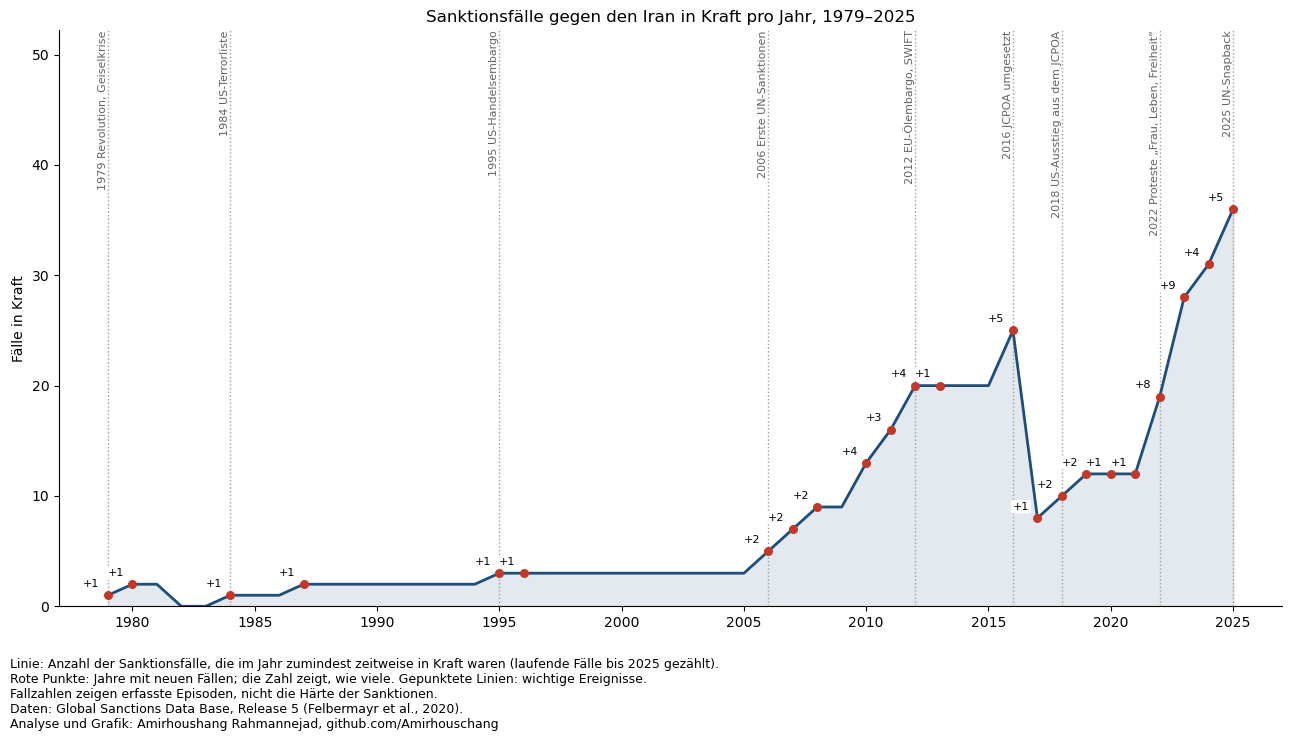

In [4]:
years = range(1979, 2026)
active_per_year = cases_in_force(iran_cases, years)
new_per_year = iran_cases.groupby("begin_year").size()

TXT_TIMELINE = {
    "en": {
        "title": "Sanction cases against Iran in force per year, 1979–2025",
        "ylabel": "Cases in force",
        "notes": [
            "Line: number of sanction cases in force at any time during the year (ongoing cases are counted up to 2025).",
            "Red points: years in which new cases were imposed; the label shows how many. Dotted lines: key events.",
            "Case counts reflect recorded episodes, not the severity of sanctions.",
        ],
    },
    "de": {
        "title": "Sanktionsfälle gegen den Iran in Kraft pro Jahr, 1979–2025",
        "ylabel": "Fälle in Kraft",
        "notes": [
            "Linie: Anzahl der Sanktionsfälle, die im Jahr zumindest zeitweise in Kraft waren (laufende Fälle bis 2025 gezählt).",
            "Rote Punkte: Jahre mit neuen Fällen; die Zahl zeigt, wie viele. Gepunktete Linien: wichtige Ereignisse.",
            "Fallzahlen zeigen erfasste Episoden, nicht die Härte der Sanktionen.",
        ],
    },
}

for lang in LANGS:
    t = TXT_TIMELINE[lang]
    events = KEY_EVENTS_DE if lang == "de" else KEY_EVENTS
    fig, ax = plt.subplots(figsize=(13, 6.5))

    # Linie und Fläche: Anzahl der Fälle in Kraft pro Jahr
    ax.plot(active_per_year.index, active_per_year.values, color=COLOR_MAIN, linewidth=2)
    ax.fill_between(active_per_year.index, active_per_year.values, color=COLOR_MAIN, alpha=0.12)

    # Punkte nur in Jahren mit neuen Fällen, beschriftet mit der Anzahl neuer Fälle
    ax.scatter(new_per_year.index, active_per_year.loc[new_per_year.index], color=COLOR_NEW, s=30, zorder=3)
    for year, n in new_per_year.items():
        ax.annotate(
            f"+{n}",
            (year, active_per_year.loc[year]),
            textcoords="offset points",
            xytext=(-6, 6),
            ha="right",
            fontsize=8,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"),
            zorder=4,
        )

    # Wichtige Ereignisse als senkrechte Linien mit Beschriftung oben
    y_top = active_per_year.max() * 1.45
    for year, label in events.items():
        ax.axvline(year, color="#9e9e9e", linestyle=":", linewidth=1, zorder=1)
        ax.text(year, y_top, f"{year} {label}", rotation=90, va="top", ha="right", fontsize=8, color=COLOR_DARK)

    ax.set_xticks(range(1980, 2030, 5))
    ax.set_xlim(1977, 2027)
    ax.set_ylim(0, y_top)
    ax.set_ylabel(t["ylabel"])
    ax.set_title(t["title"])
    ax.spines[["top", "right"]].set_visible(False)

    chart_footer(fig, t["notes"], lang, DATA_NOTE_R5)
    plt.tight_layout()
    save_chart(fig, "timeline", lang)

Um zu sehen, wie viele Fälle neu sind und wie viele aus früheren Jahren weiterlaufen, dieselben Daten als gestapelte Balken:

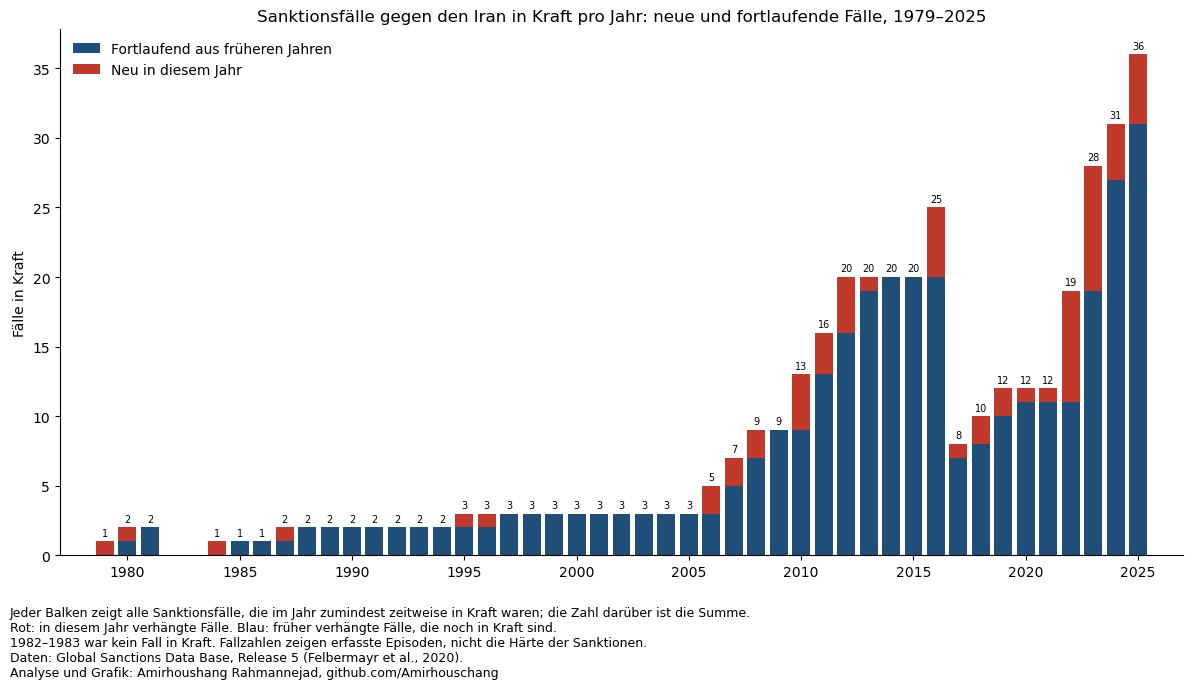

In [5]:
# Fälle in Kraft pro Jahr aufteilen in neue und fortlaufende Fälle
new_cases = iran_cases.groupby("begin_year").size().reindex(years, fill_value=0)
continuing_cases = active_per_year - new_cases

TXT_NEW_CONT = {
    "en": {
        "title": "Sanction cases against Iran in force per year: new vs. continuing, 1979–2025",
        "ylabel": "Cases in force",
        "continuing": "Continuing from earlier years",
        "new": "New in this year",
        "notes": [
            "Each bar shows all sanction cases in force at any time during that year; the number above is the total.",
            "Red: cases imposed in that year. Blue: cases imposed earlier and still in force.",
            "No case was in force in 1982–1983. Case counts reflect recorded episodes, not the severity of sanctions.",
        ],
    },
    "de": {
        "title": "Sanktionsfälle gegen den Iran in Kraft pro Jahr: neue und fortlaufende Fälle, 1979–2025",
        "ylabel": "Fälle in Kraft",
        "continuing": "Fortlaufend aus früheren Jahren",
        "new": "Neu in diesem Jahr",
        "notes": [
            "Jeder Balken zeigt alle Sanktionsfälle, die im Jahr zumindest zeitweise in Kraft waren; die Zahl darüber ist die Summe.",
            "Rot: in diesem Jahr verhängte Fälle. Blau: früher verhängte Fälle, die noch in Kraft sind.",
            "1982–1983 war kein Fall in Kraft. Fallzahlen zeigen erfasste Episoden, nicht die Härte der Sanktionen.",
        ],
    },
}

for lang in LANGS:
    t = TXT_NEW_CONT[lang]
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(continuing_cases.index, continuing_cases.values, color=COLOR_MAIN, label=t["continuing"])
    ax.bar(new_cases.index, new_cases.values, bottom=continuing_cases.values, color=COLOR_NEW, label=t["new"])

    # Summe der Fälle in Kraft über jedem Balken
    for year, total in active_per_year.items():
        if total > 0:
            ax.text(year, total + 0.4, str(total), ha="center", fontsize=7)

    ax.set_xticks(range(1980, 2030, 5))
    ax.set_xlim(1977, 2027)
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(t["title"])
    ax.set_ylabel(t["ylabel"])
    ax.legend(frameon=False, loc="upper left")

    chart_footer(fig, t["notes"], lang, DATA_NOTE_R5)
    plt.tight_layout()
    save_chart(fig, "new_vs_continuing", lang)

**Interpretation**
- **1979–2005:** meist 1 bis 3 Fälle in Kraft, keiner 1982–1983; alle von den USA verhängt (Geiselkrise, Einstufung als Terrorunterstützer, Handelsembargo).
  1982–1983 war kein Fall in Kraft: Die ersten Fälle endeten 1981 mit der Freilassung der Geiseln, der nächste begann 1984.
- **2006–2015:** starker Anstieg im Atomstreit (UN, EU und viele weitere Sender), bis zu 20 Fälle in Kraft in den Jahren 2012–2015.
- **2016:** Im Januar 2016, mit der Umsetzung des Atomabkommens (JCPOA), endeten 13 Fälle. Bis Ende 2016 waren 18 der
  25 Fälle dieses Jahres beendet, nur 7 waren noch in Kraft. Das Diagramm zeigt für 2016 trotzdem 25, weil es jeden Fall zählt,
  der im Jahr zumindest zeitweise in Kraft war; der Rückgang wird daher erst 2017 sichtbar (8 Fälle).
  Alle fünf neuen Fälle von 2016 begannen im Januar und Februar 2016; vier davon (Australien, Kanada, Schweiz, UN) haben erneut
  das Ziel Atomprogramm / Friedensbedrohung, der fünfte (Dschibuti) Politikwechsel.
- **2018–2025:** erneuter Anstieg nach dem US-Ausstieg aus dem JCPOA, mit starkem Zuwachs ab 2022
  (Proteste, Drohnenlieferungen an Russland) bis zum Höchststand von 36 Fällen im Jahr 2025.
- In den Verhandlungsjahren (2013–2015) blieb die Zahl der Fälle in Kraft konstant bei 20; sie sank erst deutlich, als
  das Abkommen im Januar 2016 umgesetzt wurde.

## 5. Wer sanktioniert den Iran?

Anzahl der Fälle gegen den Iran pro sanktionierendem Land. EU-Fälle zählen für alle Länder, die bei Beginn des Falls
EU-Mitglied waren. UN-Fälle (7) sind nicht dargestellt, weil sie keinem einzelnen Land zugeordnet werden können.

In [6]:
# ISO3-Code für jeden Sendernamen; Organisationen erhalten keinen Code
sender_names = sorted({p for s in r5["sanctioning_state"] for p in split_parties(s)})
converted = coco.convert(sender_names, to="ISO3", not_found=None)
NAME_TO_ISO3 = {
    name: HISTORICAL_STATES.get(name, code)
    for name, code in zip(sender_names, converted)
}
# country_converter gibt unbekannte Namen unverändert zurück (z. B. "EEC", "OIC"),
# daher werden nur echte ISO3-Ländercodes behalten
VALID_ISO3 = set(coco.CountryConverter().data["ISO3"])
NAME_TO_ISO3 = {name: code for name, code in NAME_TO_ISO3.items() if code in VALID_ISO3}

# Die EU und ihre Vorgängerin, die EWG, werden ihren Mitgliedsstaaten zugeordnet
EU_SENDERS = {"EU", "EEC"}


def sender_countries(sender, year, month=None):
    """Wandelt einen Sendertext in ISO3-Codes um; die EU (oder EWG) wird durch ihre Mitglieder bei Fallbeginn ersetzt.

    Die Mitgliedschaft wird nach Jahr und Monat geprüft; ist der Monat unbekannt, entscheidet das Jahr.
    """
    start = (year, MONTHS.get(month, 12))  # unbekannter Monat: gleiches Ergebnis wie eine Prüfung nur nach Jahr
    codes = set()
    for p in split_parties(sender):
        if p in EU_SENDERS:
            codes |= {
                c for c, joined in EU_MEMBERS.items()
                if joined <= start and EU_EXITS.get(c, (9999, 1)) > start
            }
        elif p in NAME_TO_ISO3:
            codes.add(NAME_TO_ISO3[p])
    return codes


# Eine Zeile pro Iran-Fall und sanktionierendem Land
iran_sender_rows = pd.DataFrame([
    {"case_id": row.case_id, "iso3": code}
    for row in iran_cases.itertuples()
    for code in sender_countries(row.sanctioning_state, row.begin_year, row.begin_month)
])

iran_senders = iran_sender_rows.groupby("iso3")["case_id"].nunique().reset_index(name="cases")
iran_senders["country"] = coco.convert(iran_senders["iso3"].tolist(), src="ISO3", to="name_short")
display(iran_senders.sort_values("cases", ascending=False, kind="stable").reset_index(drop=True))
print("UN-Fälle (nicht auf der Karte):", (iran_cases["sanctioning_state"] == "UN").sum())

TXT_IRAN_MAP = {
    "en": {
        "title": "Countries imposing sanctions on Iran, number of cases 1979–2025",
        "cases": "Cases",
        "note": "Dark grey: Iran. EU cases are assigned to all EU member states at the time of imposition. "
                "UN cases (7) are not shown. Country names as in the source data.",
    },
    "de": {
        "title": "Länder mit Sanktionen gegen den Iran, Anzahl der Fälle 1979–2025",
        "cases": "Fälle",
        "note": "Dunkelgrau: Iran. EU-Fälle zählen für alle Länder, die bei Verhängung EU-Mitglied waren. "
                "UN-Fälle (7) sind nicht dargestellt. Ländernamen wie in den Quelldaten (Englisch).",
    },
}

for lang in LANGS:
    t = TXT_IRAN_MAP[lang]
    fig = px.choropleth(
        iran_senders,
        locations="iso3",
        color="cases",
        hover_name="country",
        color_continuous_scale="Reds",
        labels={"cases": t["cases"]},
        title=t["title"],
    )

    # Iran in Dunkelgrau (eigene Ebene mit fester Farbe, ohne Farbskala)
    fig.add_trace(go.Choropleth(
        locations=["IRN"], z=[1], colorscale=[[0, COLOR_DARK], [1, COLOR_DARK]],
        showscale=False, hoverinfo="location",
    ))

    fig.update_geos(
        showframe=False,
        showcoastlines=False,
        projection_type="natural earth",
        lataxis_range=[-58, 90],  # Antarktis ausblenden
        landcolor="#f5f5f5",      # neutrale Farbe für Länder ohne Fälle
    )
    fig.update_layout(
        coloraxis_colorbar=dict(title=t["cases"]),
        height=580,
        margin=dict(l=0, r=0, t=50, b=90),
        annotations=[dict(
            x=0, y=-0.08, xref="paper", yref="paper", showarrow=False, align="left",
            text=t["note"] + "<br>" + DATA_NOTE_R5[lang] + "<br>" + AUTHOR_NOTE[lang],
            font=dict(size=10),
        )],
    )
    save_map(fig, "iran_senders_map", lang)

,iso3,cases,country
0,USA,25,United States
1,GBR,9,United Kingdom
2,AUT,8,Austria
3,BEL,8,Belgium
4,BGR,8,Bulgaria
5,CAN,8,Canada
6,CYP,8,Cyprus
7,CZE,8,Czechia
8,DEU,8,Germany
9,DNK,8,Denmark


UN-Fälle (nicht auf der Karte): 7


**Interpretation**
- Die **USA** haben 25 der 62 Fälle verhängt, gefolgt von Großbritannien (9), Kanada (8) und den EU-Mitgliedsstaaten (8).
- Alle anderen Sender sind westliche oder westlich orientierte Länder (Australien, Schweiz, Norwegen, Japan, Südkorea, Neuseeland)
  sowie Dschibuti. Kein anderes Land aus Asien, Afrika oder Lateinamerika ist als Sender eines Falls gegen den Iran erfasst
  (UN-Maßnahmen werden getrennt als UN-Fälle gezählt).
- Deutschland steht unter den sanktionierenden Ländern weltweit auf Rang 3 (einschließlich EU- und EWG-Sanktionen) und treibt Sanktionen gegen den Iran über die EU und die E3
  (Frankreich, Deutschland, Großbritannien) voran, z. B. die Rückkehr der UN-Sanktionen 2025 (siehe Abschnitt 8).

## 6. Sanktionsinstrumente

### 6.1 Instrumente insgesamt und nach Zeitraum

Jeder Fall erfasst sechs Instrumente als 0/1-Variablen. Ein Fall kann mehrere Instrumente nutzen.

,iran_cases,iran_share,world_share
Trade,44,0.710,0.414
Financial,43,0.694,0.598
Travel,27,0.435,0.315
Arms,11,0.177,0.166
Other,8,0.129,0.165
Military assistance,6,0.097,0.148


Instrumente pro Fall:
 1    19
2    20
3    17
4     2
5     3
6     1
Name: count, dtype: int64


,cases,Trade,Financial,Travel,Arms,Military assistance,Other
begin_year,,,,,,,
1979–2005,6,1.00,0.33,0.00,0.17,0.00,0.17
2006–2016,23,0.65,0.52,0.30,0.30,0.17,0.17
2017–2025,33,0.70,0.88,0.61,0.09,0.06,0.09


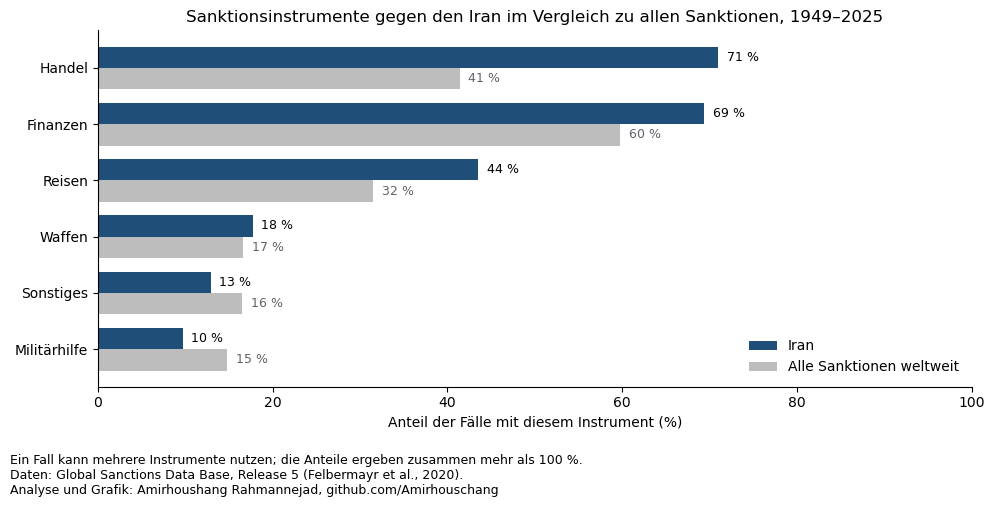

In [7]:
# Englische Bezeichnungen bleiben in den Tabellen, weil das Dashboard sie liest und übersetzt
INSTRUMENT_LABELS = {
    "trade": "Trade",
    "financial": "Financial",
    "travel": "Travel",
    "arms": "Arms",
    "military": "Military assistance",
    "other": "Other",
}
instruments = list(INSTRUMENT_LABELS)

# Anzahl und Anteil der Fälle je Instrument
instrument_table = pd.DataFrame({
    "iran_cases": iran_cases[instruments].sum(),
    "iran_share": iran_cases[instruments].mean().round(3),
    "world_share": r5[instruments].mean().round(3),
}).rename(index=INSTRUMENT_LABELS).sort_values("iran_cases", ascending=False)
display(instrument_table)

# Anzahl der Instrumente pro Iran-Fall
print("Instrumente pro Fall:\n", iran_cases[instruments].sum(axis=1).value_counts().sort_index())

# Anteil der neuen Fälle je Zeitraum, die das Instrument nutzen
periods = pd.cut(
    iran_cases["begin_year"],
    bins=[1978, 2005, 2016, 2025],
    labels=["1979–2005", "2006–2016", "2017–2025"],
)
instrument_by_period = (
    iran_cases.groupby(periods, observed=True)[instruments].mean().round(2)
    .rename(columns=INSTRUMENT_LABELS)
)
instrument_by_period.insert(0, "cases", iran_cases.groupby(periods, observed=True).size())
display(instrument_by_period)

TXT_INSTR = {
    "en": {
        "title": "Sanction instruments used against Iran compared with all sanctions, 1949–2025",
        "xlabel": "Share of cases using the instrument (%)",
        "world": "All sanctions worldwide",
        "notes": ["A case can use several instruments, so shares add up to more than 100%."],
    },
    "de": {
        "title": "Sanktionsinstrumente gegen den Iran im Vergleich zu allen Sanktionen, 1949–2025",
        "xlabel": "Anteil der Fälle mit diesem Instrument (%)",
        "world": "Alle Sanktionen weltweit",
        "notes": ["Ein Fall kann mehrere Instrumente nutzen; die Anteile ergeben zusammen mehr als 100 %."],
    },
}

# Diagramm: Anteil der Fälle je Instrument, Iran im Vergleich zur Welt
chart_data = instrument_table[["iran_share", "world_share"]].iloc[::-1] * 100

for lang in LANGS:
    t = TXT_INSTR[lang]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    y = range(len(chart_data))
    height = 0.38
    ax.barh([i + height / 2 for i in y], chart_data["iran_share"], height, color=COLOR_MAIN, label="Iran")
    ax.barh([i - height / 2 for i in y], chart_data["world_share"], height, color=COLOR_WORLD, label=t["world"])

    for i, (iran, world) in enumerate(zip(chart_data["iran_share"], chart_data["world_share"])):
        ax.text(iran + 1, i + height / 2, pct(iran, lang), va="center", fontsize=9)
        ax.text(world + 1, i - height / 2, pct(world, lang), va="center", fontsize=9, color=COLOR_DARK)

    ax.set_yticks(list(y))
    ax.set_yticklabels([lab(v, lang) for v in chart_data.index])
    ax.set_xlim(0, 100)
    ax.set_xlabel(t["xlabel"])
    ax.set_title(t["title"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")

    chart_footer(fig, t["notes"], lang, DATA_NOTE_R5)
    plt.tight_layout()
    save_chart(fig, "instruments", lang)

### 6.2 Instrumente im Zeitverlauf: Iran im Vergleich zur Welt

Anteil der Fälle in Kraft, die das jeweilige Instrument nutzen. Anteile werden nur für Jahre mit mindestens fünf Fällen in Kraft
gezeigt, deshalb beginnen die Diagramme 2006.

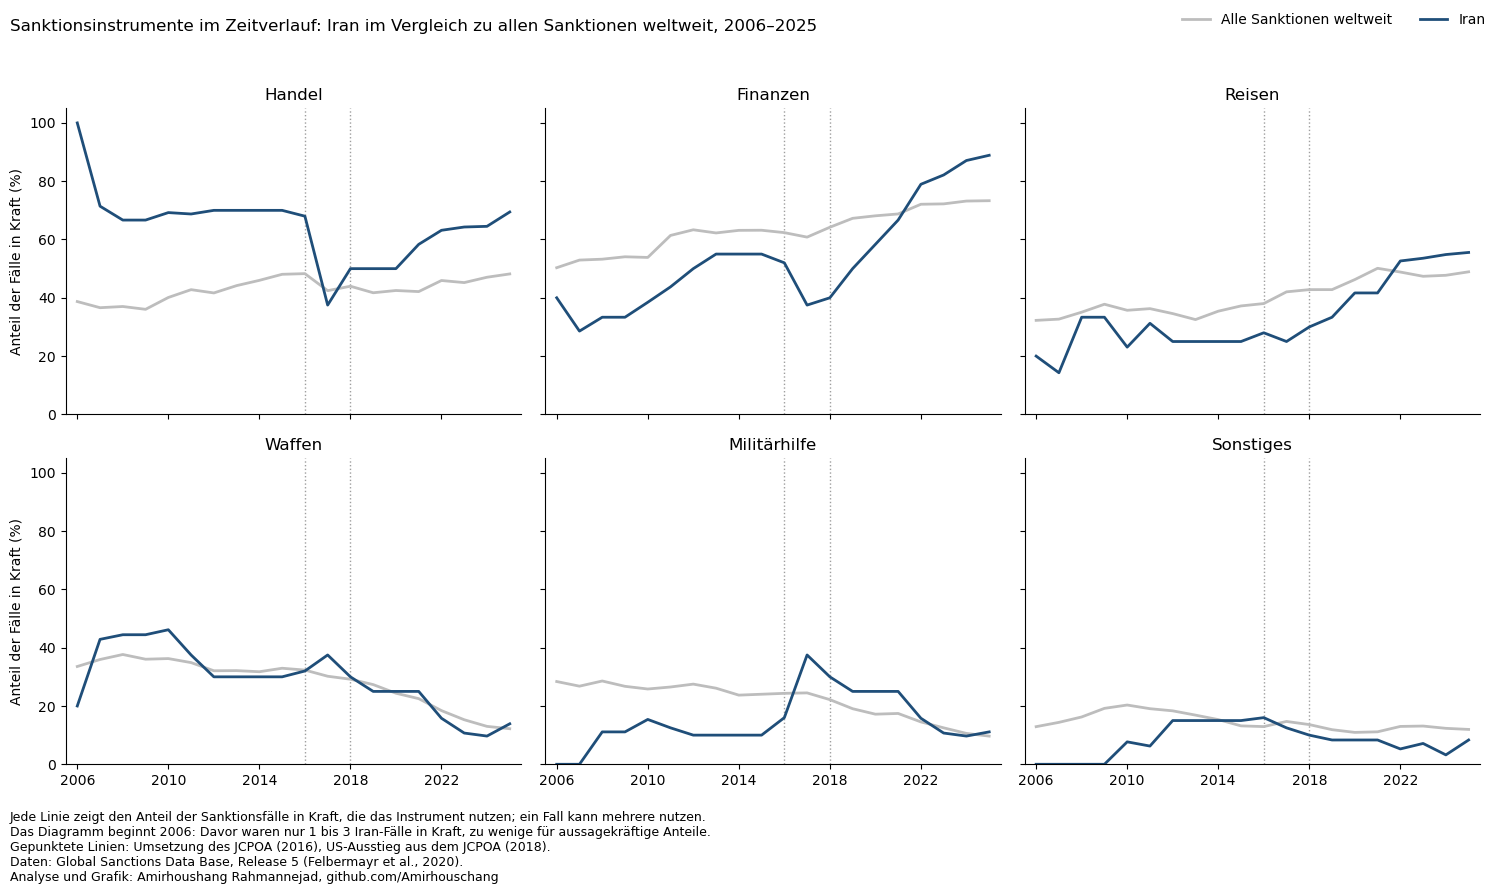

In [8]:
def share_in_force(cases, years):
    """Anteil der Fälle in Kraft pro Jahr, die ein Instrument nutzen (nur bei mindestens 5 Fällen)."""
    rows = {}
    for y in years:
        active = cases[(cases["begin_year"] <= y) & (cases["end_year"] >= y)]
        rows[y] = (
            active[instruments].mean() * 100
            if len(active) >= 5
            else pd.Series(float("nan"), index=instruments)
        )
    return pd.DataFrame(rows).T.rename(columns=INSTRUMENT_LABELS)


share_years = range(2006, 2026)
iran_share = share_in_force(iran_cases, share_years)
world_share = share_in_force(r5, share_years)

TXT_INSTR_TIME = {
    "en": {
        "title": "Sanction instruments over time: Iran vs. all sanctions worldwide, 2006–2025",
        "ylabel": "Share of cases in force (%)",
        "world": "All sanctions worldwide",
        "notes": [
            "Each line shows the share of sanction cases in force in a year that use the instrument; a case can use several.",
            "The chart starts in 2006: before that only 1–3 Iran cases were in force, too few for meaningful shares.",
            "Dotted lines: JCPOA implemented (2016), US withdrawal from the JCPOA (2018).",
        ],
    },
    "de": {
        "title": "Sanktionsinstrumente im Zeitverlauf: Iran im Vergleich zu allen Sanktionen weltweit, 2006–2025",
        "ylabel": "Anteil der Fälle in Kraft (%)",
        "world": "Alle Sanktionen weltweit",
        "notes": [
            "Jede Linie zeigt den Anteil der Sanktionsfälle in Kraft, die das Instrument nutzen; ein Fall kann mehrere nutzen.",
            "Das Diagramm beginnt 2006: Davor waren nur 1 bis 3 Iran-Fälle in Kraft, zu wenige für aussagekräftige Anteile.",
            "Gepunktete Linien: Umsetzung des JCPOA (2016), US-Ausstieg aus dem JCPOA (2018).",
        ],
    },
}

for lang in LANGS:
    t = TXT_INSTR_TIME[lang]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

    for ax, name in zip(axes.flat, INSTRUMENT_LABELS.values()):
        # Referenzlinien: Umsetzung des JCPOA (2016), US-Ausstieg (2018)
        for year in (2016, 2018):
            ax.axvline(year, color="#9e9e9e", linestyle=":", linewidth=1)
        ax.plot(world_share.index, world_share[name], color=COLOR_WORLD, linewidth=2, label=t["world"])
        ax.plot(iran_share.index, iran_share[name], color=COLOR_MAIN, linewidth=2, label="Iran")
        ax.set_title(lab(name, lang))
        ax.set_ylim(0, 105)
        ax.set_xticks(range(2006, 2026, 4))
        ax.set_xlim(2005.5, 2025.5)
        ax.spines[["top", "right"]].set_visible(False)

    for ax in axes[:, 0]:
        ax.set_ylabel(t["ylabel"])

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", frameon=False, ncol=2)
    fig.suptitle(t["title"], x=0.01, ha="left")

    chart_footer(fig, t["notes"], lang, DATA_NOTE_R5, y=-0.01)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    save_chart(fig, "instruments_over_time", lang)

**Interpretation**
- **Handelssanktionen** sind gegen den Iran viel häufiger als weltweit (71 % gegenüber 41 % der Fälle); bis 2005 enthielt jeder Iran-Fall eine Handelssanktion.
- **Finanzsanktionen** stiegen von jedem dritten neuen Fall (1979–2005) auf fast neun von zehn (2017–2025).
  Seit 2022 liegt ihr Anteil über dem weltweiten Niveau (2021: 67 % gegenüber 69 %; 2025: 89 % gegenüber 73 %).
- **Reisesanktionen** beginnen 2006 und liegen ab 2022 über dem weltweiten Anteil, meist Maßnahmen gegen Personen nach den Protesten.
- **Waffensanktionen** spielten vor allem im Atomstreit (2006–2016) eine Rolle und folgen sonst dem weltweiten Muster.
- Die meisten Fälle kombinieren Instrumente: 43 von 62 Fällen nutzen mindestens zwei.

### 6.3 Finanzsanktionen im Detail (GSDB-FS)

GSDB-FS unterteilt die Finanzkomponente in sechs Unterarten. Ein Fall kann mehrere haben.
Die Unterarten stehen nicht in fester Reihenfolge in den Daten, deshalb wird jede Unterart einzeln auf Vorhandensein geprüft.

,iran_cases,iran_share,world_share
Asset freeze,37,0.860,0.618
Financial services,35,0.814,0.456
Investment restrictions,11,0.256,0.118
Other,4,0.093,0.019
Payment infrastructure (e.g. SWIFT),2,0.047,0.017
Aid,2,0.047,0.325


,financial_cases,Asset freeze,Financial services,Investment restrictions,Payment infrastructure (e.g. SWIFT),Aid,Other
begin_year,,,,,,,
1979–2005,2,1,0,0,0,1,0
2006–2016,12,8,8,7,1,0,2
2017–2025,29,28,27,4,1,1,2


,case_id,sanctioning_state,begin_year,end_year,descr_financial
472,941,"EU, Croatia, Macedonia, Montenegro, Iceland, A...",2012,2016,"investment_restrictions, financial_services, p..."
1026,1732,EU,2025,2025,"investment_restrictions, financial_services, p..."


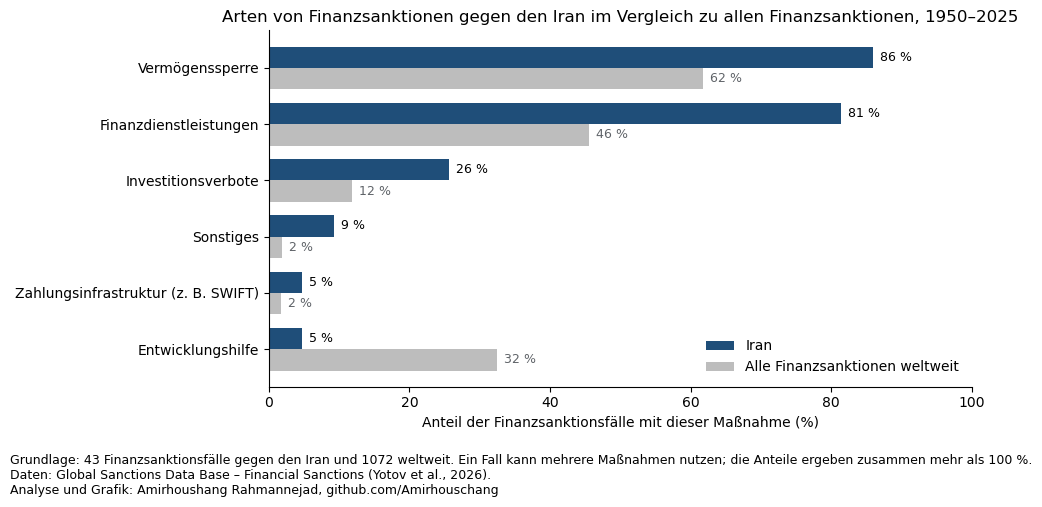

In [9]:
# Englische Bezeichnungen bleiben in den Tabellen, weil das Dashboard sie liest und übersetzt
SUBTYPE_LABELS = {
    "asset_freeze": "Asset freeze",
    "financial_services": "Financial services",
    "investment_restrictions": "Investment restrictions",
    "payment_service_infrastructure": "Payment infrastructure (e.g. SWIFT)",
    "aid": "Aid",
    "other": "Other",
}
subtypes = list(SUBTYPE_LABELS)


def add_subtype_flags(df):
    """Eine 0/1-Spalte pro Unterart (Prüfung auf Vorhandensein, da Reihenfolge und Trennzeichen variieren)."""
    df = df.copy()
    for code in subtypes:
        df[code] = df["descr_financial"].str.contains(code, regex=False).astype(int)
    return df


fs_iran_flags = add_subtype_flags(fs_iran)
fs_world_flags = add_subtype_flags(fs)

# Anzahl und Anteil der Finanzsanktionsfälle je Unterart
subtype_table = pd.DataFrame({
    "iran_cases": fs_iran_flags[subtypes].sum(),
    "iran_share": fs_iran_flags[subtypes].mean().round(3),
    "world_share": fs_world_flags[subtypes].mean().round(3),
}).rename(index=SUBTYPE_LABELS).sort_values("iran_cases", ascending=False)
display(subtype_table)

# Anzahl neuer Finanzsanktionsfälle je Zeitraum und Unterart
fs_periods = pd.cut(
    fs_iran_flags["begin_year"],
    bins=[1978, 2005, 2016, 2025],
    labels=["1979–2005", "2006–2016", "2017–2025"],
)
subtype_by_period = (
    fs_iran_flags.groupby(fs_periods, observed=True)[subtypes].sum()
    .rename(columns=SUBTYPE_LABELS)
)
subtype_by_period.insert(0, "financial_cases", fs_iran_flags.groupby(fs_periods, observed=True).size())
display(subtype_by_period)

# Fälle mit Beschränkungen der Zahlungsinfrastruktur (z. B. SWIFT)
swift_cases = fs_iran_flags[fs_iran_flags["payment_service_infrastructure"] == 1]
display(swift_cases[["case_id", "sanctioning_state", "begin_year", "end_year", "descr_financial"]])

TXT_FIN = {
    "en": {
        "title": "Types of financial sanctions against Iran compared with all financial sanctions, 1950–2025",
        "xlabel": "Share of financial sanction cases using the measure (%)",
        "world": "All financial sanctions worldwide",
        "notes": [
            f"Based on {len(fs_iran_flags)} financial sanction cases against Iran and {len(fs_world_flags)} worldwide. "
            "A case can use several measures, so shares add up to more than 100%.",
        ],
    },
    "de": {
        "title": "Arten von Finanzsanktionen gegen den Iran im Vergleich zu allen Finanzsanktionen, 1950–2025",
        "xlabel": "Anteil der Finanzsanktionsfälle mit dieser Maßnahme (%)",
        "world": "Alle Finanzsanktionen weltweit",
        "notes": [
            f"Grundlage: {len(fs_iran_flags)} Finanzsanktionsfälle gegen den Iran und {len(fs_world_flags)} weltweit. "
            "Ein Fall kann mehrere Maßnahmen nutzen; die Anteile ergeben zusammen mehr als 100 %.",
        ],
    },
}

# Diagramm: Anteil der Finanzsanktionsfälle je Unterart, Iran im Vergleich zur Welt
chart_data = subtype_table[["iran_share", "world_share"]].iloc[::-1] * 100

for lang in LANGS:
    t = TXT_FIN[lang]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    y = range(len(chart_data))
    height = 0.38
    ax.barh([i + height / 2 for i in y], chart_data["iran_share"], height, color=COLOR_MAIN, label="Iran")
    ax.barh([i - height / 2 for i in y], chart_data["world_share"], height, color=COLOR_WORLD, label=t["world"])

    for i, (iran, world) in enumerate(zip(chart_data["iran_share"], chart_data["world_share"])):
        ax.text(iran + 1, i + height / 2, pct(iran, lang), va="center", fontsize=9)
        ax.text(world + 1, i - height / 2, pct(world, lang), va="center", fontsize=9, color=COLOR_DARK)

    ax.set_yticks(list(y))
    ax.set_yticklabels([lab(v, lang) for v in chart_data.index])
    ax.set_xlim(0, 100)
    ax.set_xlabel(t["xlabel"])
    ax.set_title(t["title"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")

    chart_footer(fig, t["notes"], lang, DATA_NOTE_FS)
    plt.tight_layout()
    save_chart(fig, "financial_measures", lang)

**Interpretation**
- Finanzsanktionen gegen den Iran wirken vor allem auf der Bankenseite: **Vermögenssperren** (86 %) und Verbote von
  **Finanzdienstleistungen** (81 %) sind viel häufiger als weltweit (62 % und 46 %).
- Kürzungen von **Entwicklungshilfe** spielen fast keine Rolle (5 % gegenüber 32 % weltweit).
- **Investitionsverbote** konzentrierten sich auf die Zeit des Atomstreits (7 von 11 Fällen in 2006–2016).
- **Beschränkungen der Zahlungsinfrastruktur (z. B. SWIFT)** sind nur in zwei Fällen erfasst, beide durch die EU:
  Fall 941 (2012–2016, gemeinsam mit zehn Partnerländern) und Fall 1732 (2025, nach der Wiedereinsetzung der UN-Sanktionen).
  Das ist die GSDB-Kodierung staatlicher Sanktionen; sie erfasst nicht jede SWIFT-Maßnahme (z. B. hat SWIFT selbst
  im November 2018 bestimmte iranische Banken ausgeschlossen).
- Seit 2017 enthalten 28 von 29 neuen Finanzsanktionsfällen Vermögenssperren, meist gegen gelistete Personen und Organisationen.

## 7. Ziele und Ergebnisse

Die GSDB erfasst die erklärten Ziele jedes Falls (bis zu drei) und ein Ergebnis pro Ziel.
Ergebnisse gibt es nur für beendete Fälle; Fälle, die noch in Kraft sind, sind mit `ongoing` markiert.

status
Ongoing    36
Ended      26
Name: count, dtype: int64 



outcome,Failed,Full success,Partial success,Total
objective,,,,
Human rights,4,0,0,4
Nuclear / threat to peace,2,14,1,17
Other,0,1,0,1
Policy change,1,1,0,2
Terrorism,6,0,0,6
Total,13,16,1,30


,Iran,World
outcome,,
Full success,0.533,0.410
Partial success,0.033,0.199
Negotiated settlement,0.000,0.083
Failed,0.433,0.308


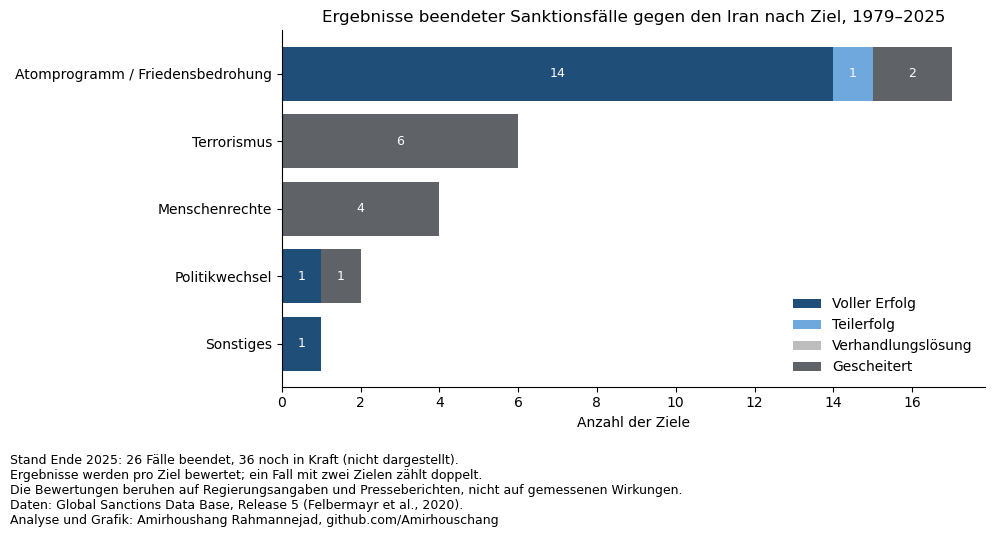

In [10]:
# Englische Bezeichnungen bleiben in den Tabellen, weil das Dashboard sie liest und übersetzt
OUTCOME_LABELS = {
    "success_total": "Full success",
    "success_part": "Partial success",
    "nego_settlement": "Negotiated settlement",
    "failed": "Failed",
}
OBJECTIVE_LABELS = {
    "prevent_war": "Nuclear / threat to peace",
    "terrorism": "Terrorism",
    "human_rights": "Human rights",
    "policy_change": "Policy change",
    "end_war": "End war",
    "democracy": "Democracy",
    "destab_regime": "Destabilise regime",
    "territorial_conflict": "Territorial conflict",
    "other": "Other",
}

# Status der Fälle Ende 2025
iran_cases["status"] = iran_cases["ongoing"].map({True: "Ongoing", False: "Ended"})
print(iran_cases["status"].value_counts(), "\n")


def outcomes_per_objective(cases):
    """Eine Zeile pro Ziel beendeter Fälle, nach Position mit dem Ergebnis verbunden."""
    ended = cases[~cases["success"].str.contains("ongoing")]
    rows = ended.assign(
        objective=ended["objective"].str.split(","),
        outcome=ended["success"].str.split(","),
    ).explode(["objective", "outcome"]).reset_index(drop=True)
    rows["objective"] = rows["objective"].str.strip()
    rows["outcome"] = rows["outcome"].str.strip().map(OUTCOME_LABELS)
    return rows


iran_outcomes = outcomes_per_objective(iran_cases)
world_outcomes = outcomes_per_objective(r5)

# Ergebnisse beendeter Iran-Fälle je Ziel
outcome_table = pd.crosstab(
    iran_outcomes["objective"].map(OBJECTIVE_LABELS),
    iran_outcomes["outcome"],
    margins=True,
    margins_name="Total",
)
display(outcome_table)

# Anteil der Ergebnisse: Iran im Vergleich zu allen Sanktionen weltweit
outcome_comparison = pd.DataFrame({
    "Iran": iran_outcomes["outcome"].value_counts(normalize=True),
    "World": world_outcomes["outcome"].value_counts(normalize=True),
}).reindex(OUTCOME_LABELS.values()).fillna(0).round(3)
display(outcome_comparison)

TXT_OUTCOMES = {
    "en": {
        "title": "Outcomes of ended sanction cases against Iran by objective, 1979–2025",
        "xlabel": "Number of objectives",
        "notes": [
            f"Status end of 2025: {(~iran_cases['ongoing']).sum()} cases ended, "
            f"{iran_cases['ongoing'].sum()} still in force (not shown).",
            "Outcomes are assessed per objective; a case with two objectives counts twice.",
            "Assessments are based on government statements and press reports, not measured effects.",
        ],
    },
    "de": {
        "title": "Ergebnisse beendeter Sanktionsfälle gegen den Iran nach Ziel, 1979–2025",
        "xlabel": "Anzahl der Ziele",
        "notes": [
            f"Stand Ende 2025: {(~iran_cases['ongoing']).sum()} Fälle beendet, "
            f"{iran_cases['ongoing'].sum()} noch in Kraft (nicht dargestellt).",
            "Ergebnisse werden pro Ziel bewertet; ein Fall mit zwei Zielen zählt doppelt.",
            "Die Bewertungen beruhen auf Regierungsangaben und Presseberichten, nicht auf gemessenen Wirkungen.",
        ],
    },
}

# Diagramm: Ergebnisse je Ziel (nur beendete Fälle)
order = ["Full success", "Partial success", "Negotiated settlement", "Failed"]
colors = [COLOR_MAIN, COLOR_LIGHT, COLOR_WORLD, COLOR_DARK]
chart_data = (
    pd.crosstab(iran_outcomes["objective"].map(OBJECTIVE_LABELS), iran_outcomes["outcome"])
    .reindex(columns=order, fill_value=0)
    .loc[lambda df: df.sum(axis=1).sort_values().index]
)

for lang in LANGS:
    t = TXT_OUTCOMES[lang]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    labels_y = [lab(v, lang) for v in chart_data.index]
    left = pd.Series(0, index=chart_data.index)
    for outcome, color in zip(order, colors):
        values = chart_data[outcome]
        ax.barh(labels_y, values, left=left, color=color, label=lab(outcome, lang))
        for y, (v, l) in enumerate(zip(values, left)):
            if v > 0:
                ax.text(l + v / 2, y, str(v), ha="center", va="center", color="white", fontsize=9)
        left += values

    ax.set_title(t["title"])
    ax.set_xlabel(t["xlabel"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")

    chart_footer(fig, t["notes"], lang, DATA_NOTE_R5)
    plt.tight_layout()
    save_chart(fig, "outcomes", lang)

**Interpretation**
- Ende 2025 sind **36 von 62 Fällen noch in Kraft**; 26 sind beendet, mit 30 bewerteten Zielen.
- **Terrorismus und Menschenrechte: alle 10 bewerteten Ziele sind gescheitert.**
- **Atomprogramm / Friedensbedrohung:** 14 von 17 Zielen gelten als *voller Erfolg*, d. h. das Zielland hat die
  Forderungen des Senders vollständig angenommen (GSDB-Codebook). 13 davon gehören zu Fällen, die im Januar bis Mai 2016 nach der
  Umsetzung des JCPOA endeten; einer (UN-Fall 868) endete 2020. **Diese Bewertung ist mit großer Vorsicht zu lesen:**
  - das Ergebnis wird bei Ende eines Falls bewertet, nicht langfristig;
  - die USA haben ihre Sanktionen 2018 wieder eingesetzt; die UN (Fall 1733) und die EU (Fall 1732) haben 2025 erneut Sanktionen verhängt;
  - der Atomstreit war also nicht gelöst, auch wenn die früheren Fälle als Erfolg gelten.
- Ohne diese JCPOA-Fälle besteht die Bilanz der Sanktionen gegen den Iran vor allem aus gescheiterten Zielen.
- Beim Iran gibt es fast keine Zwischenergebnisse (1 Teilerfolg, keine Verhandlungslösung),
  während weltweit 28 % der bewerteten Ziele in einer dieser beiden Kategorien enden.

## 8. Der Iran im weltweiten Vergleich

### 8.1 Die am häufigsten sanktionierten Länder

Fälle pro Zielland, aufgeteilt nach Ziel. Fälle mit mehreren Zielländern zählen für jedes Zielland;
ein Fall mit zwei Zielen zählt in beiden Ziel-Spalten.

In [11]:
# Eine Zeile pro Fall, Zielland und Ziel
targets = r5.assign(
    target=r5["sanctioned_state"].apply(split_parties),
    objective=r5["objective"].str.split(","),
).explode("target").explode("objective")
targets["objective"] = targets["objective"].str.strip()

total_per_target = targets.groupby("target")["case_id"].nunique().rename("total_cases")
objective_per_target = targets.groupby(["target", "objective"])["case_id"].nunique().unstack(fill_value=0)

# Sortiert nach Fallzahl, bei Gleichstand alphabetisch; gleiche Fallzahl ergibt gleichen Rang
target_table = (
    pd.concat([total_per_target, objective_per_target], axis=1)
    .sort_index()
    .sort_values("total_cases", ascending=False, kind="stable")
)
target_table.insert(0, "rank", target_table["total_cases"].rank(ascending=False, method="min").astype(int))

# Top 10 der sanktionierten Länder, Iran hervorgehoben
display(
    target_table.head(10).style.apply(
        lambda row: ["background-color: #dbe7f3" if row.name == "Iran" else "" for _ in row],
        axis=1,
    )
)

# Rang des Irans je Ziel unter allen Zielländern
for col in ["prevent_war", "terrorism", "human_rights", "policy_change"]:
    rank = target_table[col].rank(ascending=False, method="min")["Iran"]
    print(f"{col}: Iran auf Rang {int(rank)} ({target_table.loc['Iran', col]} Fälle)")

,rank,total_cases,democracy,destab_regime,end_war,human_rights,other,policy_change,prevent_war,territorial_conflict,terrorism
target,,,,,,,,,,,
Russia,1,75,3,0,41,11,5,30,5,2,0
Iran,2,62,1,0,4,15,3,16,24,0,14
China,3,57,2,13,8,17,8,24,1,1,0
Belarus,4,47,21,0,18,23,1,23,0,1,0
Myanmar,5,42,12,0,3,39,3,0,0,0,0
"Korea, North",6,40,1,1,4,2,3,8,30,0,1
Cambodia,7,33,12,9,10,15,6,2,0,0,0
Pakistan,7,33,7,0,6,5,1,3,10,5,3
Israel,9,32,0,0,15,4,0,9,3,3,1


prevent_war: Iran auf Rang 2 (24 Fälle)
terrorism: Iran auf Rang 3 (14 Fälle)
human_rights: Iran auf Rang 6 (15 Fälle)
policy_change: Iran auf Rang 5 (16 Fälle)


**Interpretation**
- Der Iran ist das **am zweithäufigsten sanktionierte Land** (62 Fälle) nach Russland (75), unter 185 Zielländern.
- Der Iran hat ein breites Profil: viele Fälle zu Atomprogramm / Friedensbedrohung (Rang 2, nach Nordkorea),
  Terrorismus (Rang 3, nach Afghanistan und Libanon), Menschenrechten (Rang 6) und Politikwechsel (Rang 5).
- Die Sowjetunion (9 Fälle) ist getrennt von Russland erfasst.

### 8.2 Die wichtigsten Sanktionsakteure

Fälle pro Sender. Die EU und die UN werden hier jeweils als ein Sender gezählt.

In [12]:
# Eine Zeile pro Fall und Sender
senders = r5.assign(sender=r5["sanctioning_state"].apply(split_parties)).explode("sender")
senders["against_iran"] = senders["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)

sender_table = senders.groupby("sender").agg(
    total_cases=("case_id", "nunique"),
    first_year=("begin_year", "min"),
    last_year=("begin_year", "max"),
    cases_against_iran=("against_iran", "sum"),
)

# Jahr mit den meisten neuen Fällen pro Sender (bei Gleichstand das früheste Jahr)
cases_per_sender_year = senders.groupby(["sender", "begin_year"])["case_id"].nunique()
sender_table["peak_year"] = cases_per_sender_year.groupby(level=0).idxmax().str[1]
sender_table["cases_in_peak_year"] = cases_per_sender_year.groupby(level=0).max()

# Aktivstes Jahrzehnt pro Sender
cases_per_decade = (
    senders.assign(decade=senders["begin_year"] // 10 * 10)
    .groupby(["sender", "decade"])["case_id"].nunique()
)
sender_table["peak_decade"] = cases_per_decade.groupby(level=0).idxmax().str[1].astype(str) + "s"

# Fälle je Ziel
sender_objectives = senders.assign(objective=senders["objective"].str.split(",")).explode("objective")
sender_objectives["objective"] = sender_objectives["objective"].str.strip()
objective_per_sender = (
    sender_objectives.groupby(["sender", "objective"])["case_id"].nunique().unstack(fill_value=0)
)

# Sortiert nach Fallzahl, bei Gleichstand alphabetisch; gleiche Fallzahl ergibt gleichen Rang
sender_table = (
    sender_table.join(objective_per_sender)
    .sort_index()
    .sort_values("total_cases", ascending=False, kind="stable")
)
sender_table.insert(0, "rank", sender_table["total_cases"].rank(ascending=False, method="min").astype(int))
sender_table["iran_share"] = (sender_table["cases_against_iran"] / sender_table["total_cases"]).round(3)

display(sender_table.head(10))
display(sender_table.loc[["Iran"]])

,rank,total_cases,first_year,last_year,cases_against_iran,peak_year,cases_in_peak_year,peak_decade,democracy,destab_regime,end_war,human_rights,other,policy_change,prevent_war,territorial_conflict,terrorism,iran_share
sender,,,,,,,,,,,,,,,,,,
United States,1,686,1950,2025,25,2023,61,2020s,136,51,73,198,174,116,51,10,87,0.036
EU,2,190,1978,2025,8,2023,18,2020s,61,2,61,83,14,31,10,2,19,0.042
United Kingdom,3,120,1950,2025,5,2021,25,2020s,30,3,33,43,24,21,5,7,11,0.042
UN,4,88,1951,2025,7,1992,5,2000s,9,1,43,22,1,10,21,4,17,0.080
Canada,5,79,1966,2025,8,2023,9,2020s,20,2,10,33,13,8,12,1,3,0.101
Norway,6,62,1966,2025,3,2011,10,2010s,12,0,24,29,4,11,1,0,6,0.048
Russia,7,55,1992,2025,0,2022,9,2020s,0,1,2,2,7,44,1,2,0,0.000
Australia,8,49,1966,2025,4,2024,5,2020s,14,1,6,14,2,12,11,1,1,0.082
Iceland,8,49,1985,2025,3,2011,10,2010s,7,0,23,25,3,7,1,0,6,0.061


,rank,total_cases,first_year,last_year,cases_against_iran,peak_year,cases_in_peak_year,peak_decade,democracy,destab_regime,end_war,human_rights,other,policy_change,prevent_war,territorial_conflict,terrorism,iran_share
sender,,,,,,,,,,,,,,,,,,
Iran,53,5,1952,2023,0,2022,2,2020s,0,0,0,0,0,4,0,0,4,0.0


**Interpretation**
- Die **USA** haben 686 Fälle verhängt, fast so viele wie die nächsten neun Sender zusammen (741).
- Fast alle großen Sender sind in den 2020er Jahren am aktivsten; Ausnahmen sind die UN (2000er) sowie Norwegen,
  Liechtenstein und Island (2010er), die weit oben stehen, weil sie sich EU-Sanktionen anschließen.
- Gemessen an ihrer Gesamtzahl richten Kanada (10 %), Australien (8 %) und die UN (8 %) den größten Anteil ihrer Fälle gegen den Iran.
- Der Iran selbst hat 5 Fälle verhängt (Rang 53 von 153 Sendern, geteilt mit anderen Sendern mit 5 Fällen), siehe 8.3.
- Sender mit gleicher Fallzahl teilen sich einen Rang (z. B. Australien, Island und Liechtenstein, Rang 8).

### 8.3 Wer sanktioniert die Welt?

Alle sanktionierenden Länder auf einer Karte. Fälle der EU, einschließlich der 14 Fälle ihrer Vorgängerin, der EWG (1979–1991),
werden den Mitgliedsstaaten zum Zeitpunkt der Verhängung zugeordnet;
Fälle der UN und anderer Organisationen sind nicht dargestellt.

In [13]:
# Eine Zeile pro Fall und sanktionierendem Land (alle Fälle)
world_sender_rows = pd.DataFrame([
    {"case_id": row.case_id, "iso3": code}
    for row in r5.itertuples()
    for code in sender_countries(row.sanctioning_state, row.begin_year, row.begin_month)
])

world_senders = world_sender_rows.groupby("iso3")["case_id"].nunique().reset_index(name="cases")
world_senders["country"] = coco.convert(world_senders["iso3"].tolist(), src="ISO3", to="name_short")

organisations = [n for n in sender_names if n not in NAME_TO_ISO3 and n not in EU_SENDERS]
print("Nicht dargestellt (Organisationen):", organisations)
print(f"Fälle auf der Karte: {world_sender_rows['case_id'].nunique()} von {len(r5)}")

# Fallzahlen in Klassen einteilen, damit die Farbskala lesbar bleibt
bins = [0, 5, 20, 50, 100, float("inf")]
class_labels = ["1–5", "6–20", "21–50", "51–100", "100+"]
world_senders["class"] = pd.cut(world_senders["cases"], bins=bins, labels=class_labels)

TXT_WORLD_MAP = {
    "en": {
        "title": "Who sanctions the world? Number of sanction cases imposed per country, 1949–2025",
        "cases": "Cases",
        "note": "Grey: countries with only 1–5 cases. "
                "EU cases (incl. its predecessor, the EEC) are assigned to all member states at the time of imposition. "
                "Cases by the UN and other organisations are not shown.<br>"
                "Historical states are shown under today's successor state (e.g. Soviet Union → Russia).",
    },
    "de": {
        "title": "Wer sanktioniert die Welt? Anzahl der verhängten Sanktionsfälle pro Land, 1949–2025",
        "cases": "Fälle",
        "note": "Grau: Länder mit nur 1–5 Fällen. "
                "Fälle der EU (einschließlich ihrer Vorgängerin, der EWG) zählen für alle Länder, die bei Verhängung Mitglied waren. "
                "Fälle der UN und anderer Organisationen sind nicht dargestellt.<br>"
                "Historische Staaten erscheinen unter dem heutigen Nachfolgestaat (z. B. Sowjetunion → Russland).",
    },
}

for lang in LANGS:
    t = TXT_WORLD_MAP[lang]
    fig = px.choropleth(
        world_senders.sort_values("cases"),
        locations="iso3",
        color="class",
        hover_name="country",
        hover_data={"cases": True, "iso3": False, "class": False},
        labels={"cases": t["cases"]},
        category_orders={"class": class_labels},
        color_discrete_sequence=["#d9d9d9", "#fcae91", "#fb6a4a", "#de2d26", "#a50f15"],
        title=t["title"],
    )
    fig.update_geos(
        showframe=False,
        showcoastlines=False,
        projection_type="natural earth",
        lataxis_range=[-58, 90],  # Antarktis ausblenden
        landcolor="#f5f5f5",      # neutrale Farbe für Länder ohne Fälle
    )
    fig.update_layout(
        legend_title_text=t["cases"],
        height=640,
        margin=dict(l=0, r=0, t=50, b=110),
        annotations=[dict(
            x=0, y=-0.1, xref="paper", yref="paper", showarrow=False, align="left",
            text=t["note"] + "<br>" + DATA_NOTE_R5[lang] + "<br>" + AUTHOR_NOTE[lang],
            font=dict(size=10),
        )],
    )
    save_map(fig, "world_senders_map", lang)

# Eigene Fälle: Land selbst als Sender genannt (EU-/EWG-Mitgliedschaft nicht gezählt)
own_sender_rows = pd.DataFrame([
    {"case_id": row.case_id, "iso3": NAME_TO_ISO3[p]}
    for row in r5.itertuples()
    for p in split_parties(row.sanctioning_state)
    if p in NAME_TO_ISO3
]).drop_duplicates()
own_cases = own_sender_rows.groupby("iso3")["case_id"].nunique()

# Fälle gegen den Iran je sanktionierendem Land (einschließlich EU-Mitgliedschaft)
iran_case_ids = set(iran_cases["case_id"])
against_iran = world_sender_rows[world_sender_rows["case_id"].isin(iran_case_ids)].groupby("iso3")["case_id"].nunique()

# Rangliste der sanktionierenden Länder (gleiche Fallzahl ergibt gleichen Rang)
sender_ranking = world_senders.sort_values(["cases", "country"], ascending=[False, True]).reset_index(drop=True)
sender_ranking.insert(0, "rank", sender_ranking["cases"].rank(ascending=False, method="min").astype(int))
sender_ranking["own_cases"] = sender_ranking["iso3"].map(own_cases).fillna(0).astype(int)
sender_ranking["via_eu"] = sender_ranking["cases"] - sender_ranking["own_cases"]
sender_ranking["against_iran"] = sender_ranking["iso3"].map(against_iran).fillna(0).astype(int)
sender_ranking = sender_ranking[["rank", "country", "iso3", "cases", "own_cases", "via_eu", "against_iran", "class"]]
display(sender_ranking.head(15))
print("Keine Länder, getrennt aufgeführt: EU", sender_table.loc["EU", "total_cases"], "Fälle, UN", sender_table.loc["UN", "total_cases"], "Fälle")

# Iran als sanktionierendes Land: Rang, Klasse und Zielländer
display(sender_ranking[sender_ranking["iso3"] == "IRN"])
display(iran_as_sender[["case_id", "sanctioned_state", "begin_year", "end_year", "objective", "success"]])

Nicht dargestellt (Organisationen): ['African Union', 'CSCE', 'ChinCom', 'CoCom', 'Commonwealth', 'ECCAS', 'ECOWAS', 'G7', 'G8', 'Kimberly Process Participants', 'League of Arab States', 'MERCOSUR', 'NAFTA', 'NATO', 'OAPEC', 'OIC', 'OSCE', 'Organisation of African Unity', 'Organization of American States', 'Organization of Eastern Caribbean States', 'Pacific Islands Forum', 'Paris Agreement Signatories', 'SADC', 'UN', 'UNASUR']
Fälle auf der Karte: 1607 von 1794


,rank,country,iso3,cases,own_cases,via_eu,against_iran,class
0,1,United States,USA,686,686,0,25,100+
1,2,United Kingdom,GBR,261,120,141,9,100+
2,3,Germany,DEU,241,38,203,8,100+
3,4,France,FRA,240,37,203,8,100+
4,5,Denmark,DNK,222,18,204,8,100+
5,5,Netherlands,NLD,222,18,204,8,100+
6,7,Belgium,BEL,212,8,204,8,100+
7,7,Italy,ITA,212,9,203,8,100+
8,9,Spain,ESP,209,12,197,8,100+
9,10,Greece,GRC,206,4,202,8,100+


Keine Länder, getrennt aufgeführt: EU 190 Fälle, UN 88 Fälle


,rank,country,iso3,cases,own_cases,via_eu,against_iran,class
57,57,Iran,IRN,5,5,0,0,1–5


,case_id,sanctioned_state,begin_year,end_year,objective,success
29,30,United Kingdom,1952,1953,policy_change,nego_settlement
703,704,Argentina,2003,2007,terrorism,success_total
1350,1351,Canada,2022,2025,"policy_change,terrorism","ongoing,ongoing"
1442,1443,United States,2022,2025,"policy_change,terrorism","ongoing,ongoing"
1473,1474,EU,2023,2025,"policy_change,terrorism","ongoing,ongoing"


### 8.4 Die EU als Sanktionsakteur

Die EU ist nach den USA der zweitgrößte Sanktionsakteur der Welt.
Dieser Abschnitt betrachtet zuerst die EU-Sanktionen insgesamt und dann die EU-Fälle gegen den Iran.

EU-Fälle: 190 (Rang 2 von 153 Sendern)
   Ende 2025 noch in Kraft: 92
   erster Fall: 1978
EWG-Fälle (getrennt aufgeführt): 14 (1979–1991)


,new_cases
begin_year,
1970s,1
1990s,38
2000s,43
2010s,45
2020s,63


,rank,cases
target,,
Belarus,1,12
Russia,2,11
Iran,3,8
Myanmar,3,8
Afghanistan,5,6
China,5,6
"Congo, Democratic Republic of the",5,6
Sudan,5,6
Burundi,9,5


,cases
objective,
Human rights,83
Democracy,61
End war,61
Policy change,31
Terrorism,19
Other,14
Nuclear / threat to peace,10
Destabilise regime,2
Territorial conflict,2


,eu_share,world_share
Trade,0.316,0.414
Financial,0.768,0.598
Travel,0.495,0.315
Arms,0.279,0.166
Military assistance,0.189,0.148
Other,0.116,0.165


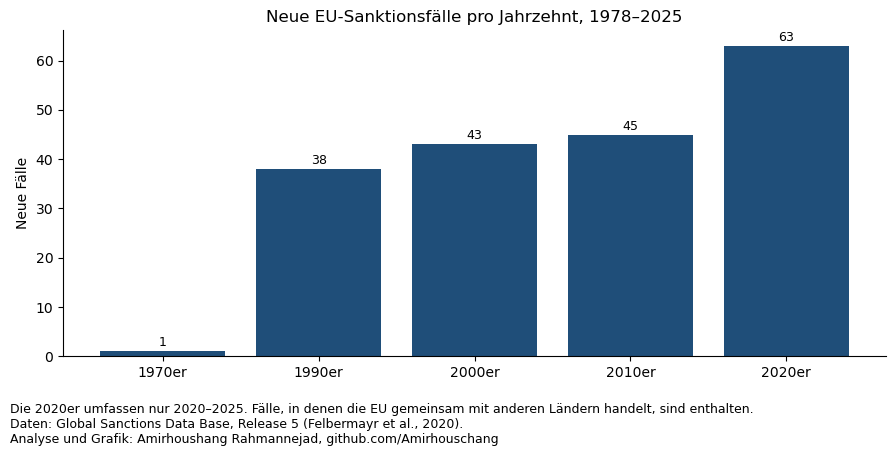

In [14]:
# Alle EU-Fälle (EU als Sender genannt, allein oder gemeinsam mit anderen Ländern)
eu_cases = senders[senders["sender"] == "EU"].drop_duplicates("case_id").copy()
eu_cases["ongoing"] = eu_cases["success"].str.contains("ongoing")

print("EU-Fälle:", len(eu_cases), f"(Rang {sender_table.loc['EU', 'rank']} von {len(sender_table)} Sendern)")
print("   Ende 2025 noch in Kraft:", eu_cases["ongoing"].sum())
print("   erster Fall:", eu_cases["begin_year"].min())

# Fälle der EWG, der Vorgängerin der EU, sind unter einem eigenen Sendernamen erfasst
eec_cases = senders[senders["sender"] == "EEC"].drop_duplicates("case_id")
print("EWG-Fälle (getrennt aufgeführt):", len(eec_cases),
      f"({eec_cases['begin_year'].min()}–{eec_cases['begin_year'].max()})")

# Neue EU-Fälle pro Jahrzehnt
eu_per_decade = eu_cases.groupby(eu_cases["begin_year"] // 10 * 10).size()
eu_per_decade.index = eu_per_decade.index.astype(str) + "s"
display(eu_per_decade.rename("new_cases").to_frame())

# Hauptzielländer der EU-Sanktionen (Fälle mit mehreren Zielländern zählen für jedes)
eu_targets = (
    eu_cases.assign(target=eu_cases["sanctioned_state"].apply(split_parties))
    .explode("target")["target"].value_counts()
    .sort_index().sort_values(ascending=False, kind="stable")  # bei Gleichstand alphabetisch
)
eu_top_targets = eu_targets.head(10).rename("cases").to_frame()
eu_top_targets.insert(0, "rank", eu_targets.rank(ascending=False, method="min").astype(int).head(10))
display(
    eu_top_targets.style.apply(
        lambda row: ["background-color: #dbe7f3" if row.name == "Iran" else "" for _ in row],
        axis=1,
    )
)

# Ziele der EU-Sanktionen (ein Fall mit zwei Zielen zählt doppelt)
eu_objectives = eu_cases["objective"].str.split(",").explode().str.strip().map(
    lambda o: OBJECTIVE_LABELS.get(o, o)
)
display(eu_objectives.value_counts().rename("cases").to_frame())

# Instrumente der EU im Vergleich zu allen Sanktionen weltweit
eu_instruments = pd.DataFrame({
    "eu_share": eu_cases[instruments].mean().round(3),
    "world_share": r5[instruments].mean().round(3),
}).rename(index=INSTRUMENT_LABELS)
display(eu_instruments)

TXT_EU_DECADES = {
    "en": {
        "title": "New EU sanction cases per decade, 1978–2025",
        "ylabel": "New cases",
        "notes": ["The 2020s cover only 2020–2025. Cases in which the EU acts together with other countries are included."],
    },
    "de": {
        "title": "Neue EU-Sanktionsfälle pro Jahrzehnt, 1978–2025",
        "ylabel": "Neue Fälle",
        "notes": ["Die 2020er umfassen nur 2020–2025. Fälle, in denen die EU gemeinsam mit anderen Ländern handelt, sind enthalten."],
    },
}

# Diagramm: neue EU-Fälle pro Jahrzehnt
for lang in LANGS:
    t = TXT_EU_DECADES[lang]
    decade_labels = [d.replace("s", "er") for d in eu_per_decade.index] if lang == "de" else list(eu_per_decade.index)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(decade_labels, eu_per_decade.values, color=COLOR_MAIN)
    for x, v in zip(decade_labels, eu_per_decade.values):
        ax.text(x, v + 1, str(v), ha="center", fontsize=9)
    ax.set_title(t["title"])
    ax.set_ylabel(t["ylabel"])
    ax.spines[["top", "right"]].set_visible(False)
    chart_footer(fig, t["notes"], lang, DATA_NOTE_R5)
    plt.tight_layout()
    save_chart(fig, "eu_decades", lang)

**Interpretation**
- Die EU hat seit 1978 **190 Fälle** verhängt (Rang 2 nach den USA); 92 waren Ende 2025 noch in Kraft.
  Zusätzlich sind 14 Fälle aus 1979–1991 unter der EWG, der Vorgängerin der EU, erfasst; sie sind in den 190 nicht enthalten.
- Fast alle EU-Sanktionen stammen aus der Zeit ab 1990, mit den meisten neuen Fällen in den 2020er Jahren.
- Die EU sanktioniert vor allem wegen Menschenrechten, Demokratie und zur Beendigung von Kriegen und nutzt Finanz- (77 % gegenüber 60 %),
  Reise- (50 % gegenüber 32 %) und Waffenmaßnahmen (28 % gegenüber 17 %) häufiger als der weltweite Durchschnitt, Handelsmaßnahmen seltener (32 % gegenüber 41 %).
- Ihre wichtigsten Zielländer sind Belarus (12) und Russland (11), gefolgt von Myanmar und dem Iran (je 8).

**EU-Sanktionen gegen den Iran**

In [15]:
# EU-Fälle gegen den Iran mit Ziel, Ergebnis und Instrumenten
eu_iran = eu_cases[eu_cases["sanctioned_state"].str.contains(IRAN_PATTERN, na=False)].copy()
eu_iran["instruments"] = eu_iran[instruments].apply(
    lambda row: ", ".join(INSTRUMENT_LABELS[i] for i in instruments if row[i] == 1), axis=1
)
eu_iran = eu_iran.merge(fs[["case_id", "descr_financial"]], on="case_id", how="left")

print("EU-Fälle gegen den Iran:", len(eu_iran), "von", len(iran_cases), "Iran-Fällen")
display(
    eu_iran[["case_id", "begin_year", "end_year", "objective", "success", "instruments", "descr_financial"]]
    .sort_values("begin_year")
    .reset_index(drop=True)
)

EU-Fälle gegen den Iran: 8 von 62 Iran-Fällen


,case_id,begin_year,end_year,objective,success,instruments,descr_financial
0,806,2007,2016,prevent_war,success_total,Arms,NaN
1,901,2011,2016,human_rights,failed,"Financial, Travel",asset_freeze
2,940,2012,2016,human_rights,failed,Trade,NaN
3,941,2012,2016,policy_change,failed,"Trade, Financial, Other","investment_restrictions, financial_services, p..."
4,1372,2022,2025,human_rights,ongoing,"Trade, Financial, Travel","asset_freeze, financial_services"
5,1373,2022,2025,end_war,ongoing,"Trade, Financial, Travel","asset_freeze, financial_services"
6,1489,2023,2025,policy_change,ongoing,"Trade, Financial, Travel","asset_freeze, financial_services"
7,1732,2025,2025,policy_change,ongoing,"Trade, Financial, Travel, Arms, Other","investment_restrictions, financial_services, p..."


**Interpretation**
- Die EU hat **8 der 62 Fälle** gegen den Iran verhängt, in zwei Wellen: 2007–2012 (Atomprogramm, Menschenrechte,
  Politikwechsel) und 2022–2025 (Niederschlagung der Proteste, Drohnenlieferungen an Russland, Rückkehr der UN-Sanktionen).
- Laut GSDB-Kodierung endeten die vier Fälle der ersten Welle im Januar 2016: Der Atomfall gilt als Erfolg,
  die drei anderen als gescheitert. Die vier Fälle seit 2022 sind noch in Kraft.
- Ein kodiertes Ende heißt nicht, dass alle Maßnahmen endeten: Das EU-Menschenrechtssanktionsregime gegen den Iran von 2011
  wird seitdem jedes Jahr verlängert (Rat der EU, 2026). In den Daten beginnt der nächste EU-Menschenrechtsfall gegen den Iran
  2022 (Fall 1372).
- Beide Fälle mit Beschränkungen der Zahlungsinfrastruktur (z. B. SWIFT) gegen den Iran wurden von der EU verhängt, 2012 und 2025.

### 8.5 Deutschland als Sanktionsakteur

Auf der Karte steht Deutschland **weltweit auf Rang 3 (241 Fälle)**, nach den USA und Großbritannien (241 enthält einen Fall der ehemaligen DDR;
ohne ihn teilen sich Deutschland und Frankreich mit je 240 Fällen Rang 3). Der größte Teil stammt aus
EU- und EWG-Sanktionen, die Deutschland gemeinsam mit den anderen Mitgliedsstaaten beschließt. Die nächste Zelle trennt die eigenen
nationalen Fälle Deutschlands davon.

In [16]:
# Eigene Fälle Deutschlands (als Sender genannt, allein oder mit anderen Ländern; EU-Fälle ausgenommen)
germany_own = senders[senders["sender"] == "Germany"].drop_duplicates("case_id")
germany_rank = sender_ranking.loc[sender_ranking["iso3"] == "DEU", ["rank", "cases"]]

print("Deutschland, Rang und Fälle einschließlich EU:", germany_rank.to_dict("records"))
print("Deutschland, eigene nationale Fälle:", len(germany_own))
print("   davon gegen den Iran:", germany_own["sanctioned_state"].str.contains(IRAN_PATTERN, na=False).sum())
print("   erstes und letztes Jahr:", germany_own["begin_year"].min(), "–", germany_own["begin_year"].max())

# Sanktionen gegen Israel: Welche EU-Akteure erscheinen als Sender?
eu_names = {"EU", "Germany"} | {
    name for name, iso in NAME_TO_ISO3.items() if iso in EU_MEMBERS and iso != "GBR"
}
israel_cases = senders[senders["sanctioned_state"].str.contains(r"\bIsrael\b", na=False)]
israel_eu = israel_cases[israel_cases["sender"].isin(eu_names)]

print("\nFälle gegen Israel (alle Sender):", israel_cases["case_id"].nunique())
print("   durch die EU:", (israel_cases["sender"] == "EU").sum())
print("   durch Deutschland:", (israel_cases["sender"] == "Germany").sum())
display(israel_eu[["case_id", "sender", "begin_year", "objective"]].sort_values("begin_year"))

Deutschland, Rang und Fälle einschließlich EU: [{'rank': 3, 'cases': 241}]
Deutschland, eigene nationale Fälle: 37
   davon gegen den Iran: 0
   erstes und letztes Jahr: 1949 – 2025

Fälle gegen Israel (alle Sender): 32
   durch die EU: 0
   durch Deutschland: 0


,case_id,sender,begin_year,objective
15,16,France,1950,prevent_war
127,128,France,1967,territorial_conflict
1006,1007,Spain,2014,prevent_war
1739,1740,Netherlands,2025,policy_change
1743,1744,Slovenia,2025,end_war
1744,1745,Spain,2025,end_war


**Interpretation**
- Deutschland hat **37 eigene nationale Fälle** (1949–2025), **keinen gegen den Iran**. Gegen den Iran handelt Deutschland über die EU
  (8 Fälle) und als Teil der E3 mit Frankreich und Großbritannien: Im August 2025 haben die E3 die Rückkehr der
  UN-Sanktionen gegen den Iran ausgelöst („Snapback“), in den Daten als UN-Fall 1733 erfasst.
- Nach dem Zeitraum der Daten hat Deutschland die Einstufung der Revolutionsgarden (IRGC) als Terrororganisation durch die EU
  stark unterstützt: Die EU-Außenminister einigten sich am 29. Januar 2026 politisch, und der Rat
  nahm die IRGC am 19. Februar 2026 formell in die EU-Terrorliste auf.
- Zum Vergleich: Die Daten erfassen keinen Fall gegen Israel durch die EU oder durch Deutschland; nationale Maßnahmen gegen Israel
  haben einige EU-Mitgliedsstaaten ergriffen (Frankreich 1950 und 1967, Spanien 2014 und 2025, die Niederlande und Slowenien 2025).
  Ein Vorschlag Spaniens, Sloweniens und Irlands, das EU-Israel-Assoziierungsabkommen auszusetzen, wurde im April 2026
  nicht angenommen, nachdem Deutschland und Italien widersprochen hatten.

### 8.6 Vergleich mit nicht-westlichen Ländern

Dieselben Kennzahlen für China, Russland (einschließlich Sowjetunion), Saudi-Arabien, Indien, die Türkei und den Iran als Sender.
`top_targets` und `top_objectives` zeigen jeweils die drei häufigsten Werte; bei Gleichstand auf Rang 3 wird alphabetisch gekürzt.

In [17]:
compare = {
    "China": "CHN", "Russia": "RUS", "Saudi Arabia": "SAU",
    "India": "IND", "Turkey": "TUR", "Iran": "IRN",
}

# Sender, deren Fälle für das jeweilige Land gezählt werden (Russland einschließlich Sowjetunion)
sender_aliases = {"Russia": ["Russia", "Soviet Union"]}

def top_counts(values, n=3):
    """Die n häufigsten Werte; bei Gleichstand alphabetisch geordnet."""
    return values.value_counts().sort_index().sort_values(ascending=False, kind="stable").head(n)


comparison_rows = []
for country, iso in compare.items():
    names = sender_aliases.get(country, [country])
    cases = senders[senders["sender"].isin(names)].drop_duplicates("case_id")
    case_targets = cases.assign(target=cases["sanctioned_state"].apply(split_parties)).explode("target")
    case_objectives = cases["objective"].str.split(",").explode().str.strip()
    ranking_row = sender_ranking[sender_ranking["iso3"] == iso]

    comparison_rows.append({
        "country": country,
        "world_rank": int(ranking_row["rank"].iloc[0]) if len(ranking_row) else None,
        "cases": len(cases),
        "first_year": cases["begin_year"].min(),
        "last_year": cases["begin_year"].max(),
        "peak_year": cases["begin_year"].value_counts().idxmax() if len(cases) else None,
        "ongoing": int(cases["success"].str.contains("ongoing").sum()),
        "against_iran": int(cases["sanctioned_state"].str.contains(IRAN_PATTERN, na=False).sum()),
        "top_targets": ", ".join(f"{t} ({n})" for t, n in top_counts(case_targets["target"]).items()),
        "top_objectives": ", ".join(f"{o} ({n})" for o, n in top_counts(case_objectives).items()),
    })

comparison_table = pd.DataFrame(comparison_rows).set_index("country")
display(comparison_table)

,world_rank,cases,first_year,last_year,peak_year,ongoing,against_iran,top_targets,top_objectives
country,,,,,,,,,
China,45,27,1967,2025,2021,16,0,"United States (5), Canada (3), Taiwan (3)","policy_change (20), democracy (2), human_right..."
Russia,31,67,1950,2025,2022,30,0,"Australia (5), Estonia (5), Ukraine (5)","policy_change (52), other (8), human_rights (4)"
Saudi Arabia,53,9,1990,2025,1990,2,0,"Lebanon (2), Canada (1), Egypt, Arab Rep. (1)","policy_change (4), terrorism (4), democracy (1)"
India,50,16,1949,2025,1954,2,0,"Pakistan (5), Portugal (5), Nepal (4)","territorial_conflict (6), democracy (4), polic..."
Turkey,47,26,1985,2024,2011,13,0,"Afghanistan (5), Somalia (3), Bulgaria (2)","end_war (15), human_rights (13), terrorism (6)"
Iran,57,5,1952,2023,2022,3,0,"Argentina (1), Canada (1), EU (1)","policy_change (4), terrorism (4)"


**Interpretation**
- **Keines dieser Länder ist als Sender eines Falls gegen den Iran erfasst.** Alle nationalen und EU-Sanktionen gegen den Iran
  stammen von westlichen oder westlich orientierten Ländern und Dschibuti. UN-Maßnahmen werden getrennt als UN-Fälle gezählt
  (7 gegen den Iran); UN-Mitgliedsstaaten wie China sind verpflichtet, sie umzusetzen.
- China und Russland sanktionieren vor allem wegen *Politikwechsel* (China 20 von 27 Fällen, Russland 52 von 67), oft als Gegenmaßnahme
  (China gegen die USA und Kanada; Russland gegen Australien, Estland, die Ukraine und Großbritannien, je 5 Fälle).
- Die Türkei folgt einem Muster, das westlichen Sendern näher ist (Kriegsende, Menschenrechte); 18 ihrer 26 Fälle wurden
  gemeinsam mit der EU verhängt.
- Indien war vor allem früh aktiv (Spitzenjahr 1954; Portugal wegen Goa, Pakistan).
- Der Iran selbst hat 5 Fälle verhängt: gegen Großbritannien (1952–53, Ölkrise), Argentinien (2003–07) sowie Kanada, die USA und die EU (2022–23).

## 9. Export für das Dashboard

Das Streamlit-Dashboard (`dashboard/app.py`) liest nur die hier exportierten **aggregierten Tabellen**: Zählungen und Anteile,
keine einzelnen Sanktionsfälle. So bleiben die GSDB-Rohdaten aus dem Repository und dem veröffentlichten Dashboard heraus.

Dateinamen, Spaltennamen und Kategorien bleiben englisch, weil das Dashboard sie so liest und selbst ins Deutsche übersetzt.

In [18]:
import json

export_dir = Path("dashboard/data")
export_dir.mkdir(parents=True, exist_ok=True)

# 4. Entwicklung im Zeitverlauf
pd.DataFrame({
    "year": list(active_per_year.index),
    "cases_in_force": active_per_year.values,
    "new_cases": new_per_year.reindex(active_per_year.index, fill_value=0).values,
}).to_csv(export_dir / "iran_timeline.csv", index=False)

pd.DataFrame(
    [{"year": year, "event": label} for year, label in KEY_EVENTS.items()]
).to_csv(export_dir / "key_events.csv", index=False)

# 5. Wer sanktioniert den Iran
iran_senders.sort_values("cases", ascending=False, kind="stable").to_csv(export_dir / "iran_senders.csv", index=False)
(
    senders[senders["against_iran"]].groupby("sender")["case_id"].nunique()
    .sort_values(ascending=False, kind="stable").rename_axis("sender").reset_index(name="cases")
    .to_csv(export_dir / "iran_sender_actors.csv", index=False)
)

# 6. Instrumente
instrument_table.rename_axis("instrument").reset_index().to_csv(export_dir / "iran_instruments.csv", index=False)
instrument_by_period.rename_axis("period").reset_index().to_csv(export_dir / "iran_instruments_by_period.csv", index=False)
pd.concat([
    iran_share.rename_axis("year").reset_index().melt(id_vars="year", var_name="instrument", value_name="share").assign(group="Iran"),
    world_share.rename_axis("year").reset_index().melt(id_vars="year", var_name="instrument", value_name="share").assign(group="World"),
]).round(1).to_csv(export_dir / "instrument_shares_over_time.csv", index=False)
subtype_table.rename_axis("subtype").reset_index().to_csv(export_dir / "financial_subtypes.csv", index=False)
subtype_by_period.rename_axis("period").reset_index().to_csv(export_dir / "financial_subtypes_by_period.csv", index=False)

# 7. Ziele und Ergebnisse
(
    iran_outcomes.assign(objective=iran_outcomes["objective"].map(OBJECTIVE_LABELS))
    .groupby(["objective", "outcome"]).size().reset_index(name="count")
    .to_csv(export_dir / "iran_outcomes.csv", index=False)
)
outcome_comparison.rename_axis("outcome").reset_index().to_csv(export_dir / "outcome_comparison.csv", index=False)

# 8. Weltweiter Vergleich
# Top 15 nach Rang (Länder mit gleichem Rang 15 sind alle enthalten)
target_table[target_table["rank"] <= 15].rename_axis("target").reset_index().to_csv(export_dir / "top_targets.csv", index=False)
sender_table[sender_table["rank"] <= 15].rename_axis("sender").reset_index().to_csv(export_dir / "top_senders.csv", index=False)
sender_ranking[sender_ranking["rank"] <= 15].to_csv(export_dir / "top_sender_countries.csv", index=False)
world_senders.to_csv(export_dir / "world_senders.csv", index=False)
eu_per_decade.rename_axis("decade").reset_index(name="new_cases").to_csv(export_dir / "eu_per_decade.csv", index=False)
eu_targets.head(10).rename_axis("target").reset_index(name="cases").to_csv(export_dir / "eu_top_targets.csv", index=False)
eu_objectives.value_counts().rename_axis("objective").reset_index(name="cases").to_csv(export_dir / "eu_objectives.csv", index=False)
eu_instruments.rename_axis("instrument").reset_index().to_csv(export_dir / "eu_instruments.csv", index=False)
comparison_table.reset_index().to_csv(export_dir / "sender_comparison.csv", index=False)

# Kennzahlen
germany_row = sender_ranking.loc[sender_ranking["iso3"] == "DEU"].iloc[0]
kpis = {
    "cases_world": int(len(r5)),
    "cases_iran": int(len(iran_cases)),
    "share_iran": round(len(iran_cases) / len(r5) * 100, 1),
    "iran_rank_target": int(target_table.loc["Iran", "rank"]),
    "iran_first_year": int(iran_cases["begin_year"].min()),
    "iran_ongoing": int(iran_cases["ongoing"].sum()),
    "iran_ended": int((~iran_cases["ongoing"]).sum()),
    "iran_cases_in_force_2025": int(active_per_year.loc[2025]),
    "iran_cases_by_us": int(sender_table.loc["United States", "cases_against_iran"]),
    "iran_cases_by_eu": int(sender_table.loc["EU", "cases_against_iran"]),
    "iran_financial_cases": int(iran_cases["financial"].sum()),
    "eu_cases": int(len(eu_cases)),
    "un_cases": int(sender_table.loc["UN", "total_cases"]),
    "eu_rank": int(sender_table.loc["EU", "rank"]),
    "eu_ongoing": int(eu_cases["ongoing"].sum()),
    "germany_rank": int(germany_row["rank"]),
    "germany_cases_incl_eu": int(germany_row["cases"]),
    "germany_own_cases": int(len(germany_own)),
}
(export_dir / "kpis.json").write_text(json.dumps(kpis, indent=2))

print("Exportiert:", sorted(p.name for p in export_dir.iterdir()))
print("Diagramme:", sorted(p.name for p in IMAGES_DIR.iterdir()))

Exportiert: ['eu_instruments.csv', 'eu_objectives.csv', 'eu_per_decade.csv', 'eu_top_targets.csv', 'financial_subtypes.csv', 'financial_subtypes_by_period.csv', 'instrument_shares_over_time.csv', 'iran_instruments.csv', 'iran_instruments_by_period.csv', 'iran_outcomes.csv', 'iran_sender_actors.csv', 'iran_senders.csv', 'iran_timeline.csv', 'key_events.csv', 'kpis.json', 'outcome_comparison.csv', 'sender_comparison.csv', 'top_sender_countries.csv', 'top_senders.csv', 'top_targets.csv', 'world_senders.csv']
Diagramme: ['eu_decades.png', 'eu_decades_de.png', 'financial_measures.png', 'financial_measures_de.png', 'instruments.png', 'instruments_de.png', 'instruments_over_time.png', 'instruments_over_time_de.png', 'iran_senders_map.html', 'iran_senders_map_de.html', 'new_vs_continuing.png', 'new_vs_continuing_de.png', 'outcomes.png', 'outcomes_de.png', 'timeline.png', 'timeline_de.png', 'world_senders_map.html', 'world_senders_map_de.html']


## 10. Wichtigste Ergebnisse

1. **Der Iran ist das am zweithäufigsten sanktionierte Land der Welt** (62 Fälle seit 1979), nach Russland.
2. **Die Sanktionen kamen in drei Phasen:** ein kleines, rein US-amerikanisches Regime (1979–2005), ein breites multilaterales Regime im
   Atomstreit (2006–2015, weitgehend beendet mit der Umsetzung des JCPOA im Januar 2016) und ein erneuter, breiterer Anstieg nach dem US-Ausstieg aus dem JCPOA (2018–2025),
   bis zum Höchststand von 36 Fällen in Kraft im Jahr 2025.
3. **Die Sender sind fast ausschließlich westlich.** Die USA allein haben 25 von 62 Fällen verhängt; China, Russland, Indien,
   Saudi-Arabien und die Türkei sind nicht als Sender eines Falls gegen den Iran erfasst (UN-Fälle werden getrennt gezählt).
4. **Die EU ist weltweit der zweitgrößte Sanktionsakteur** (190 Fälle, meist seit 1990). Der Iran gehört zu ihren
   am häufigsten sanktionierten Zielländern (8 Fälle), und beide Fälle mit Beschränkungen der Zahlungsinfrastruktur (z. B. SWIFT) gegen den Iran waren EU-Maßnahmen (2012, 2025).
5. **Deutschland steht unter den sanktionierenden Ländern weltweit auf Rang 3** (241 Fälle, einschließlich eines Falls der ehemaligen DDR), vor allem über EU- und EWG-Sanktionen. Gegen den Iran handelt es über die EU und
   die E3 (Frankreich, Deutschland, Großbritannien), die 2025 die Rückkehr der UN-Sanktionen ausgelöst haben.
6. **Die Instrumente verschoben sich vom Handel zu den Finanzen.** Finanzsanktionen stiegen von jedem dritten neuen Fall (1979–2005)
   auf fast neun von zehn (2017–2025), vor allem Vermögenssperren und Verbote von Finanzdienstleistungen.
7. **Der erfasste Erfolg ist begrenzt.** Alle bewerteten Ziele zu Terrorismus und Menschenrechten sind gescheitert. Die „Erfolge“
   beim Atomprogramm beziehen sich fast nur auf Fälle, die Anfang 2016 nach der Umsetzung des JCPOA endeten;
   die USA (2018), die UN und die EU (beide 2025) haben später erneut Sanktionen verhängt.

## 11. Limitations

- **Fallzahlen messen nicht die Härte.** Ein umfassendes Embargo zählt als ein Fall, während eine lange,
  schrittweise Verschärfung viele Fälle ergeben kann (GSDB-Codebook, Regeln zur Abgrenzung von Fällen).
- **Ergebnisse sind Bewertungen, keine Messungen.** Sie beruhen auf Regierungsangaben und Presseberichten
  und werden bei Ende eines Falls vorgenommen. Spätere Entwicklungen, etwa wieder eingesetzte Sanktionen, ändern eine frühere Bewertung nicht.
- **Wirkungen werden nicht erfasst.** Die GSDB erfasst, welche Maßnahmen verhängt wurden, nicht ihre wirtschaftlichen oder humanitären Folgen.
  Ob als gezielt beschriebene Maßnahmen (z. B. Vermögenssperren gegen Personen) auch die breite Bevölkerung trafen,
  lässt sich mit diesen Daten nicht beurteilen.
- **Für den Iran beginnen die Daten 1979.** Frühere Maßnahmen, etwa in der Ölkrise 1951–53, sind nicht als Sanktionen gegen den Iran erfasst.
- **Einschätzung der Kodierer.** Die Abgrenzung von Fällen und die Einordnung der Ziele beruhen auf Einschätzungen des GSDB-Teams.
- **Kodierte Enddaten.** Ein beendeter Fall heißt nicht immer, dass das Sanktionsregime endete; z. B. gelten die EU-Menschenrechtssanktionen
  gegen den Iran von 2011 als 2016 beendet, obwohl die EU dieses Regime jedes Jahr verlängert hat (siehe 8.4).
- **Unregelmäßigkeiten in den Daten:** `end_year` steht bei laufenden Fällen auf 2025 statt leer; einige neuere Fälle nutzen historische
  Ländernamen (*Ceylon*, *South Vietnam*, *Malaya*, *Transjordan*). Siehe Abschnitt 2.
- **Länderzuordnung auf Karten:** EU- und EWG-Fälle zählen für alle Mitgliedsstaaten zum Zeitpunkt der Verhängung
  (geprüft nach Jahr und Monat); die UN und andere
  Organisationen sind nicht dargestellt; historische Staaten erscheinen unter ihrem Nachfolgestaat.
- **Gleichstand in Ranglisten:** Sender oder Zielländer mit gleicher Fallzahl teilen sich einen Rang; innerhalb eines Gleichstands wird alphabetisch geordnet.
- **Kleine Zahlen vor 2006:** Mit nur 1 bis 3 Iran-Fällen in Kraft sind Anteile für diese Jahre nicht aussagekräftig.
- **Sprache:** Ländernamen und Kategorien in Tabellen und Exporten sind englisch wie in den Quelldaten; Diagramme gibt es auf Deutsch und Englisch.

## 12. Quellen

**Daten**
- Felbermayr, G., A. Kirilakha, C. Syropoulos, E. Yalcin, and Y. V. Yotov (2020),
  "The Global Sanctions Data Base," *European Economic Review*, 129, 103561. *(GSDB-R5)*
- Yotov, Y. V., G. Felbermayr, H. Kariem, A. Kirilakha, O. Kwon, C. Syropoulos, and E. Yalcin (2026),
  "Financial Sanctions and International Trade: Insights from New Data," Working Papers 2026014,
  Center for Global Policy Analysis, LeBow College of Business, Drexel University. *(GSDB-FS)*
- GSDB Team (2026): *Codebook GSDB-R5, Version 1.0* und *Codebook GSDB-FS, Version 1.0*.

**Kontext (Nachrichtenquellen, Deutschland und die EU)**
- Al-Monitor (28. Aug. 2025): [UK, France, Germany trigger snapback sanctions on Iran](https://www.al-monitor.com/originals/2025/08/uk-france-germany-trigger-snapback-sanctions-iran)
- Al Jazeera (13. Aug. 2025): [France, Germany and UK say they are ready to reimpose Iran sanctions](https://www.aljazeera.com/news/2025/8/13/france-germany-and-uk-say-they-are-ready-to-reimpose-iran-sanctions)
- Iran International (29. Jan. 2026): [Germany backs EU terrorism listing of the IRGC](https://www.iranintl.com/en/202601299777)
- bne IntelliNews (29. Jan. 2026): [EU designates Iran's Revolutionary Guards as terrorist organisation](https://www.intellinews.com/eu-designates-iran-s-revolutionary-guards-as-terrorist-organisation-over-protest-crackdown-423007/)
- Eunews (19. Feb. 2026): [Iran's Revolutionary Guards officially added to EU terrorist list](https://www.eunews.it/en/2026/02/19/iran-revolutionary-guards-officially-added-to-eu-terrorist-list)
- Al Jazeera (21. Apr. 2026): [Germany and Italy block bid to suspend EU-Israel trade pact](https://www.aljazeera.com/news/2026/4/21/spain-slovenia-ireland-push-eu-to-debate-israel-pact-suspension)
- Rat der EU (30. März 2026): [Human rights in Iran: Council extends sanctions regime until April 2027](https://www.consilium.europa.eu/en/press/press-releases/2026/03/30/human-rights-in-iran-council-extends-sanctions-regime-until-april-2027/)
- Swift: [Swift and sanctions](https://www.swift.com/about-us/legal/compliance-0/swift-and-sanctions)

**Datenzugang**
Die Daten sind auf Anfrage unter
[globalsanctionsdatabase.com/data](https://www.globalsanctionsdatabase.com/data/) erhältlich.
Kommerzielle Nutzung und Weitergabe sind nicht erlaubt; die Rohdaten sind daher nicht in diesem Repository enthalten.